# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [10]:
# Заповніть три поля
SURNAME_NAME = 'Ореньчук Юрій'      # прізвище та ім'я
GROUP        = 'ШІ-31'              # шифр групи, наприклад СШІ-31
NUMBER       = 15                   # ваш номер за списком групи (від 1 до 30)

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Ореньчук Юрій | ШІ-31 | номер 15


In [11]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 15   ·   Ореньчук Юрій   ·   ШІ-31

   Ринок:  Lviv
   Товар:  олія   (у наборі даних: Oil (sunflower) - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** | |
| **Підпис** | |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [12]:
# Завдання 1. Підготовка ряду
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt

mpl.rcParams.update({'font.family': 'DejaVu Sans', 'figure.figsize': (11, 3.8),
                     'axes.grid': True, 'grid.alpha': .25})

prices = pd.read_csv('ціни_україна_2014_2017.csv')
prices['date'] = pd.to_datetime(dict(year=prices['рік'], month=prices['місяць'], day=1))

GRID = pd.date_range('2014-03-01', '2017-12-01', freq='MS')

mask = (prices['ринок'] == MARKET) & (prices['товар'] == GOOD)
raw = prices[mask].set_index('date')['ціна'].sort_index()
assert raw.index.is_unique, 'у ряді є дублікати дат'
UNIT = prices.loc[mask, 'одиниця'].iloc[0]
CURRENCY = prices.loc[mask, 'валюта'].iloc[0]

series_raw = raw.reindex(GRID)              # місяць без виміру стає NaN
gaps = series_raw.index[series_raw.isna()]

print(f'Ряд: {MARKET}, {GOOD_UA} ({GOOD}); ціна в {CURRENCY} за {UNIT}')
print(f'Місяців у сітці: {len(GRID)}; із виміром: {series_raw.notna().sum()}; без виміру: {len(gaps)}')
print('Пропущені місяці у вашому ряді:', [d.strftime('%m.%Y') for d in gaps])

# чи є цей пропуск особливістю ряду чи він в усьому наборі
records_per_month = prices.groupby('date').size().reindex(GRID, fill_value=0)
print('\nЗаписів у всьому наборі (усі ринки й товари) за місяць, навколо пропуску:')
print(records_per_month['2017-06':'2017-10'].to_string())
print('Місяці сітки без жодного запису в усьому наборі:',
      [d.strftime('%m.%Y') for d in records_per_month.index[records_per_month == 0]])

Ряд: Lviv, олія (Oil (sunflower) - Retail); ціна в UAH за L
Місяців у сітці: 46; із виміром: 45; без виміру: 1
Пропущені місяці у вашому ряді: ['08.2017']

Записів у всьому наборі (усі ринки й товари) за місяць, навколо пропуску:
2017-06-01    650
2017-07-01    650
2017-08-01      0
2017-09-01    650
2017-10-01    650
Freq: MS
Місяці сітки без жодного запису в усьому наборі: ['08.2017']


**Висновок до завдання 1:**

У сітці 46 місяців виміри є за 45 з них, без виміру один місяць: серпень 2017. Пропуск у моєму ряді один, тож сітку побудовано правильно

У всьому наборі за серпень 2017 немає жодного запису. Отже, це пропуск у самому джерелі.

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

In [13]:
# Завдання 2. Заповнення пропуску
gap = gaps[0]
candidates = {
    'перенесення останнього значення': series_raw.ffill(),
    'лінійна інтерполяція':            series_raw.interpolate('linear'),
    'кубічний сплайн':                 series_raw.interpolate('cubic'),
    'значення того ж місяця торік':    series_raw.fillna(series_raw.shift(12)),
}
filled_values = pd.Series({name: s[gap] for name, s in candidates.items()})
print(f'Пропуск: {gap:%m.%Y}. Сусідні виміри: {series_raw[gap - pd.DateOffset(months=1)]:.4f} (07.2017) '
      f'і {series_raw[gap + pd.DateOffset(months=1)]:.4f} (09.2017)\n')
print(filled_values.round(4).to_string())
first_three = filled_values.iloc[:3]
print(f'\nРозкид перших трьох способів: {first_three.max() - first_three.min():.3f} {CURRENCY}/{UNIT}')
print(f'Відхилення способу "торік" від лінійної інтерполяції: '
      f'{filled_values.iloc[3] - filled_values.iloc[1]:+.3f} ({(filled_values.iloc[3] / filled_values.iloc[1] - 1) * 100:+.1f}%)')

# ОБРАНО: лінійна інтерполяція; далі в роботі використовується ряд series
series = candidates['лінійна інтерполяція'].rename('price')
assert series.notna().all() and len(series) == 46

# коли заповнювати не можна: ринки, які зникають із набору (той самий товар)
months_per_market = prices[prices['товар'] == GOOD].groupby('ринок')['date'].nunique().sort_values()
print('\nРинки, у яких для цього товару менше 45 місяців із виміром:')
print(months_per_market[months_per_market < 45].to_string())

Пропуск: 08.2017. Сусідні виміри: 31.4133 (07.2017) і 31.6167 (09.2017)

перенесення останнього значення    31.4133
лінійна інтерполяція               31.5150
кубічний сплайн                    31.4112
значення того ж місяця торік       33.5700

Розкид перших трьох способів: 0.104 UAH/L
Відхилення способу "торік" від лінійної інтерполяції: +2.055 (+6.5%)

Ринки, у яких для цього товару менше 45 місяців із виміром:
ринок
Crimea            1
m. Sevastopol     2
Luhanska         40
Donetska         42


**Висновок до завдання 2:**

Значення для пропущеного місяця (08.2017), грн за літр:

| Спосіб | Значення |
|---|---|
| перенесення останнього значення | 31.4133 |
| лінійна інтерполяція | 31.5150 |
| кубічний сплайн | 31.4112 |
| значення того ж місяця торік (08.2016) | 33.5700 |

Обрано лінійну інтерполяцію. Сусідні виміри (31.4133 у липні й 31.6167 у вересні) майже однакові, а ряд у 2017 році здебільшого тримається в 31.4 - 31.8, тому перші три способи розходяться лише на 0.104 грн, і вибір між ними майже нічого не змінює. Лінійна інтерполяція проста, не вигадує викидів і використовує вимір після пропуску, а не лише до нього. Її застосування виправдане лише для ретроспективного аналізу: у реальному прогнозі вересневого значення ще не було б. Спосіб «торік» тут є поганим: він дає на 2.055 грн більше, бо припускає сезонну повторюваність, якої в ряді немає.

Коли заповнювати неприпустимо: Коли даних немає не через випадковий збій, а тому що вимірювання припинилися. У цьому наборі так сталося з АР Крим (лише 1 місяць із 45, 03.2014), м. Севастополь (2 місяці), а також Луганською (40) та Донецькою (42) областями. Заповнення їхніх рядів вигадало б десятки цін, яких ніхто не вимірював (інтерполяція за межами відомих даних це екстраполяція), і приховало б сам факт розриву.

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

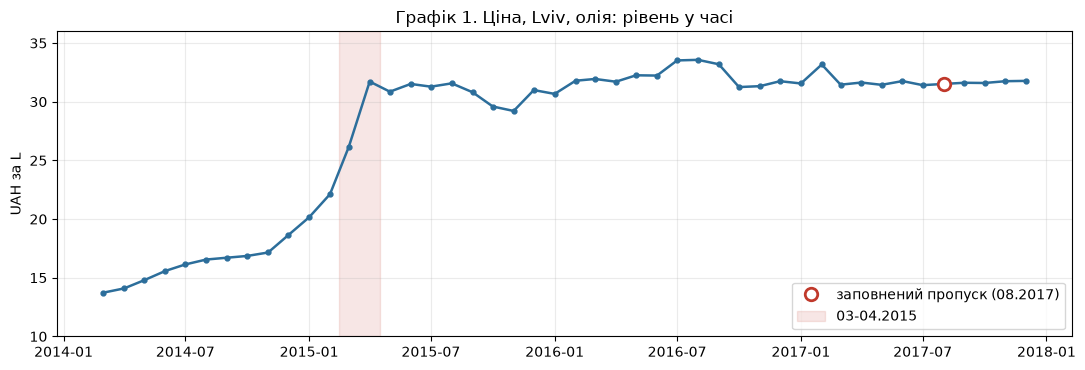

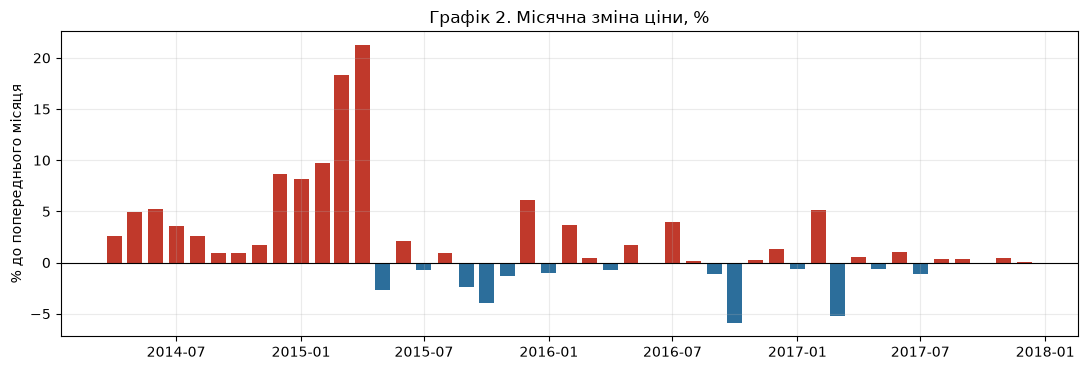

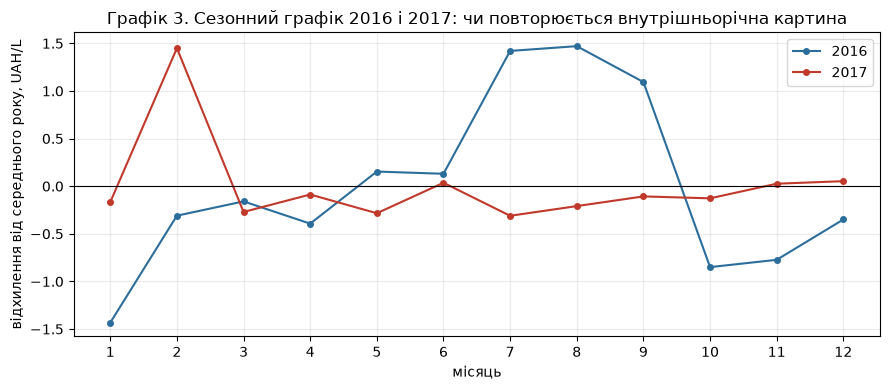

Ціна: 13.73 (03.2014) -> 31.78 (12.2017); максимум 33.57 у 08.2016
Зростання 02.2015 -> 04.2015: 22.12 -> 31.72 (x1.43)
Після 04.2015: коридор 29.21 - 33.57, розмах 14.9%
Найбільші місячні зміни, %: ['04.2015', '03.2015', '02.2015'] [21.2, 18.3, 9.8]
Кореляція внутрішньорічних відхилень 2016 і 2017: -0.20


In [14]:
# Завдання 3. Візуальна розвідка
JUMP = (pd.Timestamp('2015-03-01'), pd.Timestamp('2015-04-01'))

# 1: рівень ціни в часі
fig, ax = plt.subplots()
ax.plot(series.index, series.values, color='#2C6E9B', lw=1.8, marker='o', ms=3.5)
ax.plot([gap], [series[gap]], 'o', mfc='white', mec='#C0392B', ms=9, mew=2, label='заповнений пропуск (08.2017)')
ax.axvspan(JUMP[0] - pd.Timedelta(days=15), JUMP[1] + pd.Timedelta(days=15), color='#C0392B', alpha=.12,
           label='03-04.2015')
ax.set_ylim(10, 36); ax.set_ylabel(f'{CURRENCY} за {UNIT}')
ax.set_title(f'Графік 1. Ціна, {MARKET}, {GOOD_UA}: рівень у часі'); ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

# 2: місячна зміна у відсотках
chg = series.pct_change().dropna() * 100
fig, ax = plt.subplots()
ax.bar(chg.index, chg.values, width=22, color=np.where(chg.values >= 0, '#C0392B', '#2C6E9B'))
ax.axhline(0, color='black', lw=.8)
ax.set_ylabel('% до попереднього місяця')
ax.set_title('Графік 2. Місячна зміна ціни, %'); plt.tight_layout(); plt.show()

# 3: сезонний графік для двох повних років після стрибка (відхилення від середнього за рік)
fig, ax = plt.subplots(figsize=(9, 4))
styles = {2016: ('#2C6E9B', '-'), 2017: ('#C0392B', '-')}
dev = {}
for yr, (col, ls) in styles.items():
    part = series[str(yr)]
    dev[yr] = part - part.mean()
    ax.plot(part.index.month, dev[yr].values, color=col, ls=ls, marker='o', ms=4, label=str(yr))
ax.axhline(0, color='black', lw=.8)
ax.set_xticks(range(1, 13)); ax.set_xlabel('місяць'); ax.set_ylabel(f'відхилення від середнього року, {CURRENCY}/{UNIT}')
ax.set_title('Графік 3. Сезонний графік 2016 і 2017: чи повторюється внутрішньорічна картина'); ax.legend()
plt.tight_layout(); plt.show()

after = series['2015-04':]
print(f'Ціна: {series.iloc[0]:.2f} (03.2014) -> {series.iloc[-1]:.2f} (12.2017); максимум {series.max():.2f} у {series.idxmax():%m.%Y}')
print(f'Зростання 02.2015 -> 04.2015: {series["2015-02"].iloc[0]:.2f} -> {series["2015-04"].iloc[0]:.2f} '
      f'(x{series["2015-04"].iloc[0] / series["2015-02"].iloc[0]:.2f})')
print(f'Після 04.2015: коридор {after.min():.2f} - {after.max():.2f}, розмах {(after.max() / after.min() - 1) * 100:.1f}%')
print('Найбільші місячні зміни, %:', chg.abs().sort_values(ascending=False).head(3).index.strftime('%m.%Y').tolist(),
      chg.reindex(chg.abs().sort_values(ascending=False).head(3).index).round(1).tolist())
print(f'Кореляція внутрішньорічних відхилень 2016 і 2017: {np.corrcoef(dev[2016].values, dev[2017].values)[0, 1]:.2f}')

**Висновок до завдання 3:**

**Графік 1** Питання: як змінювався рівень ціни і коли саме. Лінія, бо місяці йдуть упорядкованою послідовністю; шкала лінійна, бо цікавить абсолютний рівень і розмір стрибка в гривнях; вісь не від нуля, бо лінія кодує положення, а не довжину. Заповнений пропуск позначено порожнім маркером, щоб не видавати його за вимір.

**Графік 2** Питання: наскільки великі місячні зміни, у який бік і чи є викиди. Стовпці з нульовою базою, бо величина зі знаком відкладається від нуля й довжина стовпця має бути пропорційна значенню; відсотки, бо вони порівнювані між 2014 і 2017 роками незалежно від рівня ціни.

**Графік 3** Питання: чи повторюється внутрішньорічна картина. Роки накладено на одну вісь місяців, щоб повтор (або його відсутність) було видно одразу; відхилення від середнього за рік прибирає різницю рівнів, спільна шкала в грн/л зберігає розмір. 2015 рік не показано, бо його профіль визначає стрибок ціни й стискає решту до лінії.

**Несподівана знахідка.** До побудови я очікував, що в олії є сезонність (бо ж урожай соняшнику), а побачив майже нерухому ціну: ціна зросла у 2.3 раза (13.73 у 03.2014 до 31.72 у 04.2015), майже все зростання припало на два місяці (+18.3% у 03.2015 і +21.2% у 04.2015), а наступні 33 місяці ціна тримається в коридорі 29.21 - 33.57 (розмах 14.9%). Профілі 2016 і 2017 років не повторюють один одного (кореляція -0.20).

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

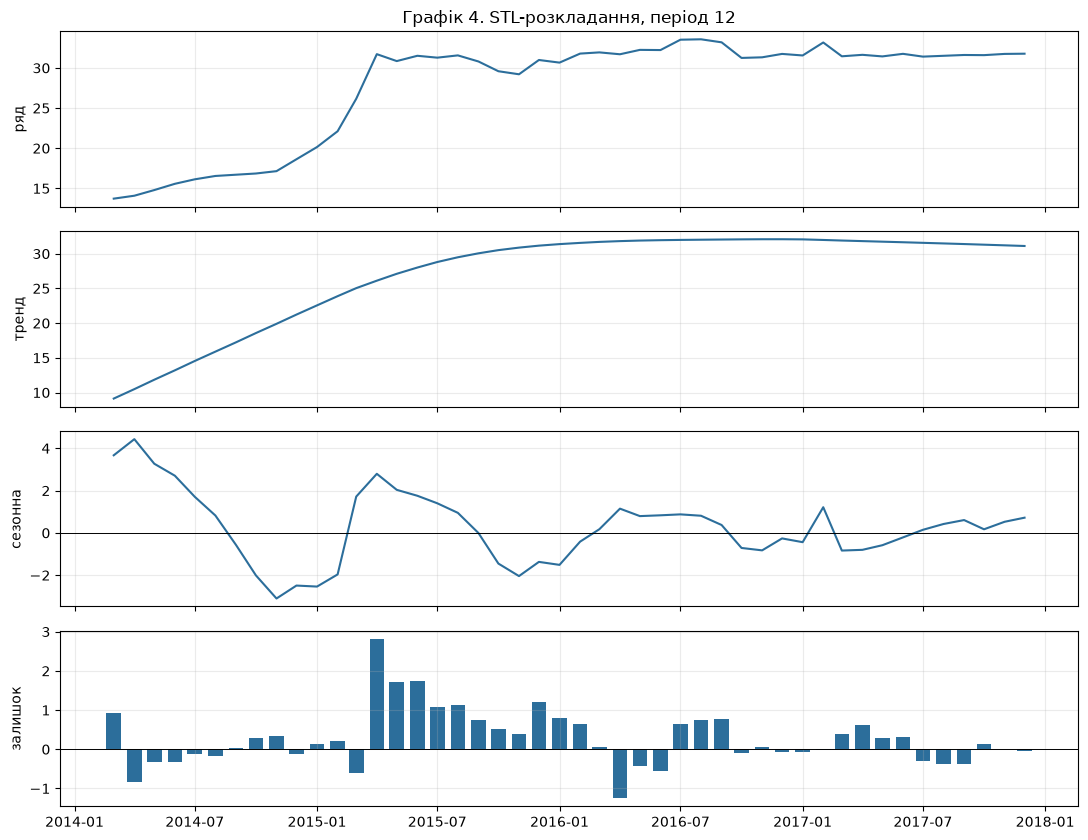

Сила сезонності F_S = 0.842   (поріг 0.64)
Сила тренду     F_T = 0.990
F_S для робастного STL = 0.445

Розмах сезонної складової (макс - мін) за роками, грн/л:
2014    7.53
2015    5.33
2016    2.66
2017    2.05
(2014 містить лише 10 місяців, 03-12)


In [16]:
# Завдання 4. Розкладання на складові
from statsmodels.tsa.seasonal import STL

stl_res = STL(series, period=12).fit()

fig, axes = plt.subplots(4, 1, figsize=(11, 8.5), sharex=True)
axes[0].plot(series.index, series.values, color='#2C6E9B'); axes[0].set_ylabel('ряд')
axes[1].plot(stl_res.trend.index, stl_res.trend.values, color='#2C6E9B'); axes[1].set_ylabel('тренд')
axes[2].plot(stl_res.seasonal.index, stl_res.seasonal.values, color='#2C6E9B'); axes[2].set_ylabel('сезонна')
axes[3].bar(stl_res.resid.index, stl_res.resid.values, width=22, color='#2C6E9B'); axes[3].set_ylabel('залишок')
axes[2].axhline(0, color='black', lw=.7); axes[3].axhline(0, color='black', lw=.7)
axes[0].set_title('Графік 4. STL-розкладання, період 12')
plt.tight_layout(); plt.show()

def strength(component, resid):
    return max(0.0, 1 - resid.var() / (component + resid).var())

Fs, Ft = strength(stl_res.seasonal, stl_res.resid), strength(stl_res.trend, stl_res.resid)
rob = STL(series, period=12, robust=True).fit()
Fs_rob = strength(rob.seasonal, rob.resid)
THRESHOLD = 0.64

print(f'Сила сезонності F_S = {Fs:.3f}   (поріг {THRESHOLD})')
print(f'Сила тренду     F_T = {Ft:.3f}')
print(f'F_S для робастного STL = {Fs_rob:.3f}')
amp = stl_res.seasonal.groupby(stl_res.seasonal.index.year).agg(lambda v: v.max() - v.min())
print('\nРозмах сезонної складової (макс - мін) за роками, грн/л:')
print(amp.round(2).to_string())
print(f'(2014 містить лише 10 місяців, 03-12)')

**Висновок до завдання 4:**

Сила сезонності F_S = 0.842, сила тренду F_T = 0.990. За прийнятим порогом 0.64 сезонність формально є, а тренд домінує: майже вся мінливість ряду пояснюється трендом.

Але я не вважаю сезонність доведеною, і ось чому. (1) За робастного STL F_S падає до 0.445, нижче порогу, тобто рішення залежить від налаштування. (2) Розмах сезонної складової не стабільний, а згасає: 5.33 грн (2015), 2.66 (2016), 2.05 (2017); справжня сезонність повторюється з порівнянною амплітудою, а спадна амплітуда типова для того, що разовий стрибок «витікає» в сезонну складову. Максимум середнього профілю припадає на квітень, тобто на місяць стрибка 2015 року. (3) Внутрішньорічні профілі 2016 і 2017 років не корелюють (-0.20, завдання 3). (4) Сезонний наївний прогноз програє наївному (MAE 1.139 проти 0.626, завдання 6). Отже, перевищення порогу це наслідок структурного зсуву 2015 року, а не доказ сезонності. Також 46 місяців це менше чотирьох повних циклів, цього замало для надійної оцінки сезонної форми.

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

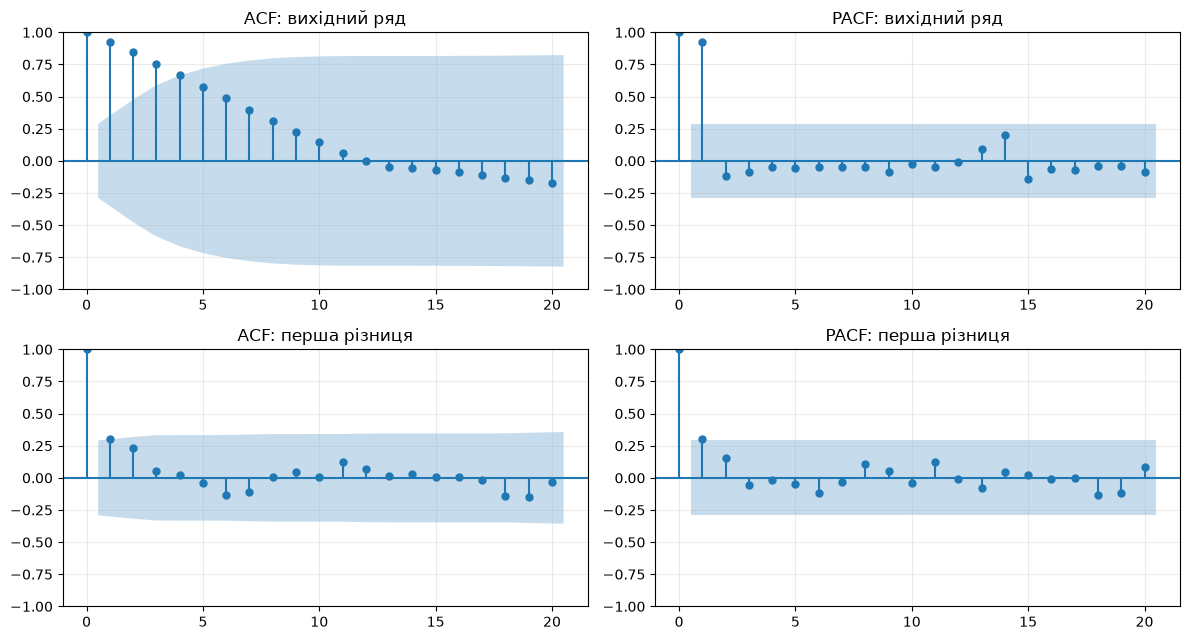

               ADF p (H0: одиничний корінь)  KPSS p (H0: стаціонарний)
вихідний ряд                         0.1603                       0.01
перша різниця                        0.0001                       0.10
Примітка: KPSS повертає p-значення, обмежене діапазоном 0.01 ... 0.10

вихідний ряд: межа значущості +-0.289
  значущі лаги ACF : [1, 2, 3, 4, 5, 6, 7, 8]
  значущі лаги PACF: [1]
  ACF лаги 1-4 : [0.93, 0.84, 0.75, 0.66]   PACF лаги 1-4: [0.93, -0.12, -0.09, -0.05]

перша різниця: межа значущості +-0.292
  значущі лаги ACF : [1]
  значущі лаги PACF: [1]
  ACF лаги 1-4 : [0.3, 0.23, 0.06, 0.02]   PACF лаги 1-4: [0.3, 0.15, -0.06, -0.01]


In [17]:
# Завдання 5. Стаціонарність
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf

d1 = series.diff().dropna()
LAGS = 20

fig, axes = plt.subplots(2, 2, figsize=(12, 6.5))
plot_acf(series, lags=LAGS, ax=axes[0, 0], title='ACF: вихідний ряд')
plot_pacf(series, lags=LAGS, ax=axes[0, 1], method='ywm', title='PACF: вихідний ряд')
plot_acf(d1, lags=LAGS, ax=axes[1, 0], title='ACF: перша різниця')
plot_pacf(d1, lags=LAGS, ax=axes[1, 1], method='ywm', title='PACF: перша різниця')
plt.tight_layout(); plt.show()

def kpss_p(x):
    with warnings.catch_warnings():              # KPSS попереджає, що p-значення обмежене таблицею
        warnings.simplefilter('ignore')
        return kpss(x, regression='c', nlags='auto')[1]

def tests(x):
    return {'ADF p (H0: одиничний корінь)': adfuller(x, autolag='AIC')[1],
            'KPSS p (H0: стаціонарний)': kpss_p(x)}

table = pd.DataFrame({'вихідний ряд': tests(series), 'перша різниця': tests(d1)}).T
print(table.round(4).to_string())
print('Примітка: KPSS повертає p-значення, обмежене діапазоном 0.01 ... 0.10')

for name, x in [('вихідний ряд', series), ('перша різниця', d1)]:
    bound = 1.96 / np.sqrt(len(x))
    a, p = acf(x, nlags=LAGS), pacf(x, nlags=LAGS, method='ywm')
    print(f'\n{name}: межа значущості +-{bound:.3f}')
    print('  значущі лаги ACF :', [l for l in range(1, LAGS + 1) if abs(a[l]) > bound])
    print('  значущі лаги PACF:', [l for l in range(1, LAGS + 1) if abs(p[l]) > bound])
    print('  ACF лаги 1-4 :', np.round(a[1:5], 2).tolist(), '  PACF лаги 1-4:', np.round(p[1:5], 2).tolist())

**Висновок до завдання 5:**

| Ряд | ADF p (H0: одиничний корінь) | KPSS p (H0: стаціонарність) | Висновок |
|---|---|---|---|
| вихідний | 0.1603 | 0.01 (не вище) | нестаціонарний |
| перша різниця | 0.0001 | 0.10 (не нижче) | стаціонарна |

Для вихідного ряду ADF не відхиляє гіпотезу про одиничний корінь (p = 0.160 > 0.05), а KPSS відхиляє гіпотезу про стаціонарність (p не вище 0.01). Нульові гіпотези протилежні, тож обидва результати кажуть одне: ряд **нестаціонарний**. Для першої різниці ADF відхиляє одиничний корінь (p = 0.0001), а KPSS не відхиляє стаціонарність (p не нижче 0.10): різниця **стаціонарна**, тобто достатньо d = 1. **Тести між собою узгоджуються**, тому пояснювати розбіжність не потрібно. Примітка: KPSS повертає p-значення, обмежене діапазоном 0.01 ... 0.10, а на 46 точках потужність обох тестів невелика.

ACF вихідного ряду повільно спадає (0.93, 0.84, 0.75, 0.66; значущі лаги 1-8), PACF має єдиний значущий лаг 1 (0.93): класична картина ряду з одиничним коренем. Після диференціювання значущим лишається лише лаг 1 (ACF 0.30 і PACF 0.30 при межі 0.292), тобто ледь вище межі.

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [18]:
# Завдання 6. Базисні прогнози та ретроспективна перевірка
y = series.values
N, N_FOLDS, STEPS = len(y), 7, 3                  # ті самі налаштування, що й в Orange
KINDS = {'naive': 'наївний', 'snaive': 'сезонний наївний', 'mean': 'середнє', 'drift': 'дрейф'}

def baseline(kind, pos, val, t):
    """Прогноз місяця t за відомими спостереженнями (позиції pos, значення val)."""
    if kind == 'naive':
        return val[-1]
    if kind == 'snaive':                           # той самий місяць торік (або раніше)
        k = 1
        while t - 12 * k >= 0:
            hit = np.where(pos == t - 12 * k)[0]
            if len(hit):
                return val[hit[0]]
            k += 1
        return val[-1]
    if kind == 'mean':
        return val.mean()
    if kind == 'drift':
        return val[-1] + (val[-1] - val[0]) / (pos[-1] - pos[0]) * (t - pos[-1])

def metrics(true, pred):
    true, pred = np.asarray(true), np.asarray(pred)
    e = true - pred
    return {'MAE': np.abs(e).mean(), 'RMSE': np.sqrt((e ** 2).mean()), 'MAPE, %': 100 * np.abs(e / true).mean()}

# хронологічні фолди: навчання y[:end], тест y[end:end+3]; навчальна частина розширюється
FOLDS = [(N - f * STEPS, N - f * STEPS + STEPS) for f in range(N_FOLDS, 0, -1)]

def rolling_origin(kind):
    T, P = [], []
    for end, stop in FOLDS:
        pos = np.arange(end)
        for t in range(end, stop):
            T.append(y[t]); P.append(baseline(kind, pos, y[:end], t))
    return metrics(T, P)

def random_split(kind, seed, test_size=12):    # 12 = ceil(0.25 * 46)
    idx = np.random.default_rng(seed).permutation(N)
    test, train = np.sort(idx[:test_size]), np.sort(idx[test_size:])
    T, P = [], []
    for t in test:
        past = train[train < t]
        if len(past) < 2:
            continue
        hist = train if kind == 'mean' else past
        T.append(y[t]); P.append(baseline(kind, hist, y[hist], t))
    return metrics(T, P)

roll = pd.DataFrame({KINDS[k]: rolling_origin(k) for k in KINDS}).T
rand = pd.DataFrame({KINDS[k]: random_split(k, seed=42) for k in KINDS}).T
print(f'Фолди (навчання -> тест): {N_FOLDS} x {STEPS} кроки; усього {N_FOLDS * STEPS} прогнозних точок\n')
print('Ретроспективна перевірка з рухомим початком:'); print(roll.round(3).to_string())
best = roll['MAE'].idxmin()
print(f'\nНайкращий базис: {best}')
print('\nВипадковий поділ 75/25 (seed 42):'); print(rand.round(3).to_string())
print('\nВідношення "випадковий поділ / рухомий початок" (<1: випадковий поділ видає меншу помилку):')
print((rand / roll).round(2).to_string())

# стабільність випадкового поділу: 300 різних розбиттів для найкращого базису
key = [k for k, v in KINDS.items() if v == best][0]
many = pd.DataFrame([random_split(key, s) for s in range(300)])
print(f'\n300 випадкових поділів, базис "{best}": MAE медіана {many["MAE"].median():.3f}, '
      f'5-95% інтервал {many["MAE"].quantile(.05):.3f} ... {many["MAE"].quantile(.95):.3f}; '
      f'рухомий початок {roll.loc[best, "MAE"]:.3f}')
print(f'Частка поділів, де помилка вища за рухомий початок: {(many["MAE"] > roll.loc[best, "MAE"]).mean():.0%}')

Фолди (навчання -> тест): 7 x 3 кроки; усього 21 прогнозних точок

Ретроспективна перевірка з рухомим початком:
                    MAE   RMSE  MAPE, %
наївний           0.626  0.886    1.944
сезонний наївний  1.139  1.384    3.543
середнє           5.981  6.190   18.628
дрейф             1.254  1.533    3.949

Найкращий базис: наївний

Випадковий поділ 75/25 (seed 42):
                    MAE   RMSE  MAPE, %
наївний           0.492  0.750    1.733
сезонний наївний  2.946  4.928    9.497
середнє           5.723  6.154   23.116
дрейф             0.438  0.503    1.474

Відношення "випадковий поділ / рухомий початок" (<1: випадковий поділ видає меншу помилку):
                   MAE  RMSE  MAPE, %
наївний           0.79  0.85     0.89
сезонний наївний  2.59  3.56     2.68
середнє           0.96  0.99     1.24
дрейф             0.35  0.33     0.37

300 випадкових поділів, базис "наївний": MAE медіана 0.854, 5-95% інтервал 0.444 ... 1.782; рухомий початок 0.626
Частка поділів, де помилка ви

**Висновок до завдання 6:**

| Базис | MAE | RMSE | MAPE, % |
|---|---|---|---|
| наївний | **0.626** | **0.886** | **1.944** |
| сезонний наївний | 1.139 | 1.384 | 3.543 |
| середнє | 5.981 | 6.190 | 18.628 |
| дрейф | 1.254 | 1.533 | 3.949 |

**Найкращий базис: наївний** (за всіма трьома метриками). Це пояснюється властивостями ряду: після квітня 2015 ціна майже не змінюється й поводиться як випадкове блукання (одиничний корінь, різниця майже не має структури), тому найкращий прогноз це останнє відоме значення. Сезонний наївний програє, бо стійкої сезонності немає. Середнє дає помилку близько 6 грн, бо в навчальну вибірку входять низькі ціни 2014 року, а рівень уже змінився. Дрейф програє, бо переносить середній нахил усієї історії (близько +0.4 грн на місяць, який створив стрибок 2015 року) на пласку ділянку.

**Випадковий поділ 75/25** (seed 42, 12 тестових місяців) дає для наївного MAE 0.492, RMSE 0.750, MAPE 1.733%, тобто в **0.79, 0.85 і 0.89 раза** від оцінки з рухомим початком (помилка здається в 1.27, 1.18 і 1.12 раза меншою). Але ця оцінка нестабільна: на 300 різних випадкових поділах MAE наївного коливається від 0.444 до 1.782 (5-95%), а в 77% поділів вона вища за 0.626. Для інших базисів відношення сягає від 0.35 (дрейф) до 2.59 (сезонний наївний), а в поділі з seed 42 «найкращим» навіть виглядає дрейф (MAE 0.438 проти 0.492). Причина: випадкові тестові місяці то потрапляють у бурхливий 2014-2015 рік, то ні, і вони не відтворюють реального горизонту прогнозу. Тож випадковий поділ для часових рядів не придатний. Застереження: серпень 2017 у фолді 2 оцінюється відносно заповненого значення.

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

                             MAE   RMSE  MAPE, % MAE, зміна vs базис
ARIMA(1,1,1)               0.684  0.877    2.133               +9.3%
найкращий базис (наївний)  0.626  0.886    1.944               +0.0%

Перша різниця, межа +-0.292: ACF лаг 1 = 0.303, лаг 2 = 0.231, лаг 3 = 0.057; PACF лаг 1 = 0.303, лаг 2 = 0.154, лаг 3 = -0.056
Значущі лаги ACF : [1]
Значущі лаги PACF: [1]
Власний порядок (1, 1, 0) на тих самих фолдах: MAE = 0.737, RMSE = 0.908, MAPE, % = 2.297
ACF першої різниці без весни 2015 (з 06.2015): лаг 1 = -0.195 (межа +-0.352)


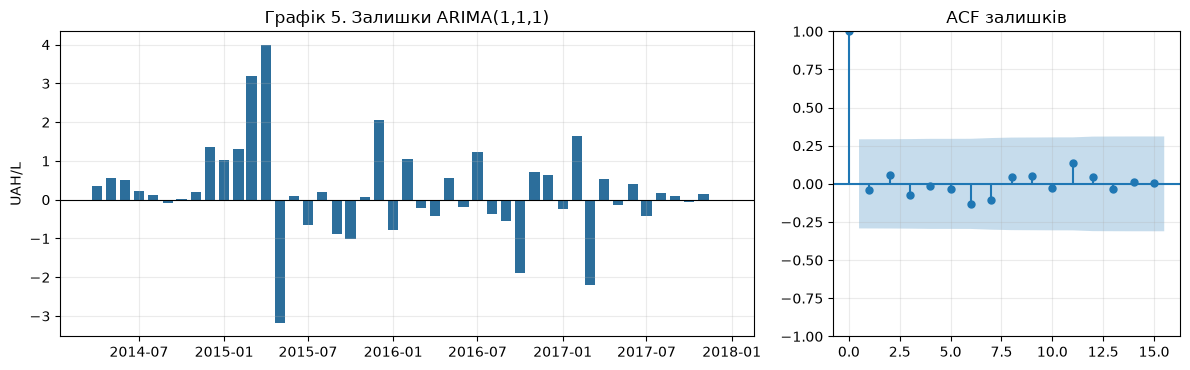

Ljung-Box (10 лагів): p = 0.992
Найбільші за модулем залишки: ['04.2015', '03.2015', '05.2015'] [3.99, 3.19, -3.17]
Стандартне відхилення залишків: 2014-2015 1.479; 2016-2017 0.863


In [19]:
# Завдання 7. Модель ARIMA
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf

def arima_rolling(order):
    T, P = [], []
    for end, stop in FOLDS:
        fit = ARIMA(y[:end], order=order).fit()
        P.extend(fit.forecast(STEPS)); T.extend(y[end:stop])
    return np.array(T), np.array(P)

arima_true, arima_pred = arima_rolling((1, 1, 1))
arima_m = metrics(arima_true, arima_pred)
cmp_tab = pd.DataFrame({'ARIMA(1,1,1)': arima_m, f'найкращий базис ({best})': roll.loc[best]}).T
cmp_tab['MAE, зміна vs базис'] = (cmp_tab['MAE'] / roll.loc[best, 'MAE'] - 1).map('{:+.1%}'.format)
print(cmp_tab.round(3).to_string())

# порядок за виглядом ACF/PACF першої різниці
d1 = series.diff().dropna()
bound = 1.96 / np.sqrt(len(d1))
a, p = acf(d1, nlags=15), pacf(d1, nlags=15, method='ywm')
print(f'\nПерша різниця, межа +-{bound:.3f}: ACF лаг 1 = {a[1]:.3f}, лаг 2 = {a[2]:.3f}, лаг 3 = {a[3]:.3f}; '
      f'PACF лаг 1 = {p[1]:.3f}, лаг 2 = {p[2]:.3f}, лаг 3 = {p[3]:.3f}')
print('Значущі лаги ACF :', [l for l in range(1, 16) if abs(a[l]) > bound])
print('Значущі лаги PACF:', [l for l in range(1, 16) if abs(p[l]) > bound])
OWN_ORDER = (1, 1, 0)
own = metrics(*arima_rolling(OWN_ORDER))
print(f'Власний порядок {OWN_ORDER} на тих самих фолдах: ' + ', '.join(f'{k} = {v:.3f}' for k, v in own.items()))
a_late = acf(d1['2015-06':], nlags=3)
print(f'ACF першої різниці без весни 2015 (з 06.2015): лаг 1 = {a_late[1]:.3f} (межа +-{1.96 / np.sqrt(len(d1["2015-06":])):.3f})')

# залишки ARIMA(1,1,1) на всьому ряді (перший залишок - ініціалізація, не враховуємо)
full_fit = ARIMA(y, order=(1, 1, 1)).fit()
resid = pd.Series(full_fit.resid[1:], index=series.index[1:])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={'width_ratios': [2, 1]})
axes[0].bar(resid.index, resid.values, width=22, color='#2C6E9B'); axes[0].axhline(0, color='black', lw=.8)
axes[0].set_title('Графік 5. Залишки ARIMA(1,1,1)'); axes[0].set_ylabel(f'{CURRENCY}/{UNIT}')
plot_acf(resid, lags=15, ax=axes[1], title='ACF залишків')
plt.tight_layout(); plt.show()
lb = acorr_ljungbox(resid, lags=[10], return_df=True)
print(f'Ljung-Box (10 лагів): p = {lb["lb_pvalue"].iloc[0]:.3f}')
print('Найбільші за модулем залишки:', resid.abs().sort_values(ascending=False).head(3).index.strftime('%m.%Y').tolist(),
      resid.reindex(resid.abs().sort_values(ascending=False).head(3).index).round(2).tolist())
print(f'Стандартне відхилення залишків: 2014-2015 {resid[:"2015-12"].std():.3f}; 2016-2017 {resid["2016-01":].std():.3f}')

**Висновок до завдання 7:**

ARIMA(1,1,1) на 7 фолдах по 3 кроки: MAE 0.684, RMSE 0.877, MAPE 2.133%. Найкращий базис (наївний): MAE 0.626, RMSE 0.886, MAPE 1.944%.

ARIMA гірша за наївний на 9.3% за MAE і на 9.7% за MAPE та краща лише на 1.0% за RMSE (0.877 проти 0.886), а на 21 прогнозній точці така різниця не відрізняється від шуму. Висновок: ця модель не має права на існування, бо складніша за наївний прогноз і не дає помітного виграшу.

**Порядок за ACF/PACF.** Перша різниця стаціонарна (завдання 5), тому d = 1. Значущим є лише лаг 1 і в ACF (0.303), і в PACF (0.303) при межі 0.292, тож за формальним правилом обрав би **ARIMA(1,1,0)** (обидві функції «обриваються» після лагу 1; еквівалентний варіант (0,1,1)). Але значущість лагу 1 тримається на двох послідовних великих приростах весни 2015 року: якщо взяти різницю з 06.2015, ACF лагу 1 стає -0.195 при межі 0.352, тобто структура зникає, і ряд практично є випадковим блуканням ARIMA(0,1,0), прогноз якого збігається з наївним. Перевірка (1,1,0) на тих самих фолдах: MAE 0.737, RMSE 0.908, MAPE 2.297%, тобто гірше й за наївний, і за (1,1,1).

**Залишки.** Тест Люнга-Бокса (10 лагів) дає p = 0.992, автокореляції в залишках не лишилося. Структура лишилася в іншому: дисперсія непостійна (стандартне відхилення залишків 1.479 у 2014-2015 і 0.863 у 2016-2017), найбільші залишки припадають на 04.2015 (+3.99), 03.2015 (+3.19) та 05.2015 (-3.17). Це зсув рівня 2015 року, який ARIMA без додаткових засобів не моделює.

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

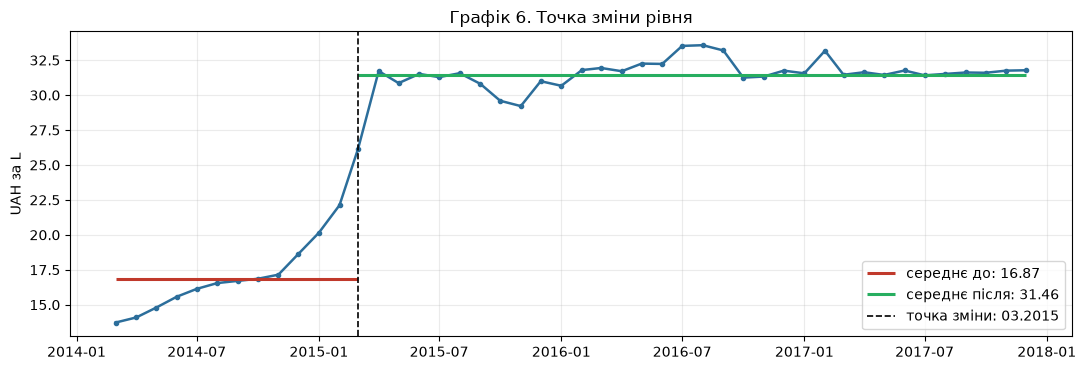

Точка зміни (t-статистика зі спільною дисперсією): 03.2015, t = 26.2
Середнє до: 16.87; після: 31.46; зсув +14.59 (1.86 раза)
Тест із випадковою перестановкою місячних змін (1000 разів): 95-й процентиль max|t| = 20.3, p = 0.004
Для порівняння, t з окремими дисперсіями (Welch) обирає 01.2015
Найбільші місячні зміни в одиницях робастного розкиду: {'04.2015': 9.5, '03.2015': 6.9, '02.2015': 3.4}
Типова місячна зміна (медіана модуля): 0.38 UAH/L; зміни 03.2015 і 04.2015: +4.04 і +5.56
Сезонний сплеск для порівняння: 02.2017 +5.1%, 03.2017 -5.2%; 02.2016 +3.7%, 03.2016 +0.5%
Мінімум ціни після 03.2015: 26.16, тобто вищий за максимум до зсуву 22.12


In [20]:
# Завдання 8. Точка зміни режиму
from scipy import stats

MIN_SEG = 6                                        # мінімум спостережень з кожного боку

def scan_t(x, welch=False):
    ks = np.arange(MIN_SEG, len(x) - MIN_SEG + 1)
    return ks, np.array([stats.ttest_ind(x[k:], x[:k], equal_var=not welch).statistic for k in ks])

ks, ts = scan_t(y)
i = int(np.argmax(np.abs(ts)))
k_star, t_star = ks[i], ts[i]
cp_date = series.index[k_star]
before, after = y[:k_star].mean(), y[k_star:].mean()

# значущість: найбільша |t| проти нульового розподілу, де місячні зміни переставлено випадково
rng = np.random.default_rng(42)
diffs = np.diff(y)
null_max = np.array([np.abs(scan_t(y[0] + np.r_[0, np.cumsum(rng.permutation(diffs))])[1]).max() for _ in range(1000)])
p_shuffle = (null_max >= abs(t_star)).mean()
ks_w, ts_w = scan_t(y, welch=True)
k_w = ks_w[int(np.argmax(np.abs(ts_w)))]

# розмір місячних змін у робастних одиницях
d = pd.Series(diffs, index=series.index[1:])
mad_sigma = 1.4826 * np.median(np.abs(d - d.median()))
z = (d / mad_sigma).sort_values(ascending=False)

fig, ax = plt.subplots()
ax.plot(series.index, y, color='#2C6E9B', lw=1.8, marker='o', ms=3)
ax.hlines(before, series.index[0], cp_date, color='#C0392B', lw=2.2, label=f'середнє до: {before:.2f}')
ax.hlines(after, cp_date, series.index[-1], color='#27AE60', lw=2.2, label=f'середнє після: {after:.2f}')
ax.axvline(cp_date, color='black', ls='--', lw=1.2, label=f'точка зміни: {cp_date:%m.%Y}')
ax.set_ylabel(f'{CURRENCY} за {UNIT}'); ax.set_title('Графік 6. Точка зміни рівня'); ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

print(f'Точка зміни (t-статистика зі спільною дисперсією): {cp_date:%m.%Y}, t = {t_star:.1f}')
print(f'Середнє до: {before:.2f}; після: {after:.2f}; зсув {after - before:+.2f} ({after / before:.2f} раза)')
print(f'Тест із випадковою перестановкою місячних змін (1000 разів): 95-й процентиль max|t| = {np.quantile(null_max, .95):.1f}, '
      f'p = {p_shuffle:.3f}')
print(f'Для порівняння, t з окремими дисперсіями (Welch) обирає {series.index[k_w]:%m.%Y}')
print('Найбільші місячні зміни в одиницях робастного розкиду:', {k.strftime('%m.%Y'): round(v, 1) for k, v in z.head(3).items()})
print(f'Типова місячна зміна (медіана модуля): {d.abs().median():.2f} {CURRENCY}/{UNIT}; '
      f'зміни 03.2015 і 04.2015: {d["2015-03"].iloc[0]:+.2f} і {d["2015-04"].iloc[0]:+.2f}')
c = series.pct_change() * 100
print(f'Сезонний сплеск для порівняння: 02.2017 {c["2017-02"].iloc[0]:+.1f}%, 03.2017 {c["2017-03"].iloc[0]:+.1f}%; '
      f'02.2016 {c["2016-02"].iloc[0]:+.1f}%, 03.2016 {c["2016-03"].iloc[0]:+.1f}%')
print(f'Мінімум ціни після {cp_date:%m.%Y}: {series[cp_date:].min():.2f}, тобто вищий за максимум до зсуву {y[:k_star].max():.2f}')

**Висновок до завдання 8:**

**Точка зміни: 03.2015**, t-статистика (спільна дисперсія, не менше 6 спостережень з кожного боку) **t = 26.2**. Середній рівень до зсуву **16.87**, після **31.46** грн/л, зсув **+14.59** (у 1.86 раза).

**Чи значуща.** Так. Звичайне p-значення тут некоректне (ряд автокорельований і ми перебираємо всі дати), тому я порівняв отримане t із розподілом максимуму |t|, побудованим 1000 випадковими перестановками місячних змін: 95-й процентиль 20.3, а спостережене 26.2, p = 0.004. Додаткові докази: місячні зміни 03.2015 (+4.04) і 04.2015 (+5.56) у 6.9 і 9.5 раза більші за типовий розкид (типова місячна зміна близько 0.38 грн), а мінімум ціни після зсуву (26.16) вищий за максимум до нього (22.12). Застереження: перебір із окремими дисперсіями (Welch) обирає 01.2015, бо зростання почалося вже в грудні 2014 - лютому 2015 (+8.6%, +8.2%, +9.8%). Тому коректніше говорити про перехід на новий рівень протягом грудня 2014 - квітня 2015 з піком у 03-04.2015, а не про точковий стрибок.

**Відмінність від сезонного сплеску.** Сезонний сплеск повертається: у 02.2017 ціна виросла на 5.1%, а вже в 03.2017 впала на 5.2%, тобто повернулася до колишнього рівня (і він не повторився у 02.2016, де за зростанням +3.7% не було падіння). Зсув рівня не відкочується: після 03.2015 ціна жодного разу не повернулася до рівнів 2014 року й 33 місяці тримається біля нового значення. Також він єдиний, а сезонний сплеск мав би повторюватися щороку в ті самі місяці.

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

In [21]:
# Завдання 9. Рецензія на чужий аналіз: перевірка тверджень звіту на тому самому ряді (гречка, Вінниця)
from statsmodels.tsa.seasonal import STL as _STL

def get(market, good):
    return prices[(prices['ринок'] == market) & (prices['товар'] == good)].sort_values('date').set_index('date')['ціна']

gr = get('Vinnytsia', 'Buckwheat grits - Retail')
beef = get('Vinnytsia', 'Meat (beef) - Retail')
gr_lviv = get('Lviv', 'Buckwheat grits - Retail')
gr_full = gr.reindex(GRID)
print('[In 2] Спостережень:', len(gr), 'із', len(GRID), '; немає виміру за', [d.strftime('%m.%Y') for d in GRID.difference(gr.index)])
print('       gr.isna().sum() у звіті =', gr.isna().sum(), '(сітку не застосовано), після reindex =', gr_full.isna().sum())

print('\n[In 4] MAE наївного прогнозу в грн і відносно середнього рівня ціни:')
for name, x in [('гречка', gr), ('яловичина', beef)]:
    e = (x - x.shift(1)).dropna().abs()
    print(f'       {name:10s} MAE = {e.mean():.2f} грн, середня ціна {x.mean():.1f} грн, MAE/середня = {e.mean() / x.mean() * 100:.1f}%')

print('\n[In 5] Кореляція Вінниця-Львів: рівні r = %.3f; місячні зміни r = %.3f' % (gr.corr(gr_lviv), gr.diff().corr(gr_lviv.diff())))

print('\n[In 6] Сила сезонності F_S, робастний STL на тих самих 45 точках, що й у звіті:')
g = gr_full.interpolate()
r = _STL(gr, period=12, robust=True).fit()          # як у звіті: на 45 точках
print('       F_S = %.2f (поріг 0.64); розмах сезонної складової %.2f грн при середній ціні %.1f грн'
      % (max(0, 1 - r.resid.var() / (r.seasonal + r.resid).var()), r.seasonal.max() - r.seasonal.min(), gr.mean()))

print('\n[In 7] Тести стаціонарності:')
print('       ADF на рівнях: p = %.3f; KPSS на рівнях: p = %.3f' % (adfuller(g, autolag='AIC')[1], kpss_p(g)))
print('       ADF на 1-й різниці: p = %.4f; KPSS на 1-й різниці: p = %.3f' % (adfuller(g.diff().dropna(), autolag='AIC')[1], kpss_p(g.diff().dropna())))

zz = (gr - gr.mean()) / gr.std()
print('\n[In 8] Місяців із |z| > 1.3: %d; із |z| > 2: %d; перелік (>1.3): %s'
      % ((zz.abs() > 1.3).sum(), (zz.abs() > 2).sum(), ', '.join(d.strftime('%m.%Y') for d in gr[zz.abs() > 1.3].index)))

print('\n[In 9] Коректна оцінка тієї ж задачі (рухомий початок, 7 x 3, ряд із заповненим пропуском):')
yg = g.values
Tt, Pa, Pn = [], [], []
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for f in range(7, 0, -1):
        e_ = len(yg) - f * 3
        Pa.extend(ARIMA(yg[:e_], order=(1, 1, 1)).fit().forecast(3)); Tt.extend(yg[e_:e_ + 3]); Pn.extend([yg[e_ - 1]] * 3)
Tt, Pa, Pn = map(np.array, (Tt, Pa, Pn))
print('       MAE ARIMA(1,1,1) = %.2f грн; MAE наївного = %.2f грн (звіт стверджував 8.73 грн для ARIMA)' % (np.abs(Tt - Pa).mean(), np.abs(Tt - Pn).mean()))

fc = ARIMA(gr.values, order=(2, 2, 1)).fit().forecast(12)
print('\n[In 10] Останнє спостереження: %.2f грн; прогноз ARIMA(2,2,1): через 1 міс. %.2f, через 6 міс. %.2f, через 12 міс. %.2f'
      % (gr.values[-1], fc[0], fc[5], fc[-1]))

w = gr['2016-01':'2016-06']
print('\n[In 11] 01-06.2016: %.2f -> %.2f грн (+%.0f%%); вісь Y у звіті починається з %.2f замість 0'
      % (w.iloc[0], w.iloc[-1], (w.iloc[-1] / w.iloc[0] - 1) * 100, w.min() * 0.995))

[In 2] Спостережень: 45 із 46 ; немає виміру за ['08.2017']
       gr.isna().sum() у звіті = 0 (сітку не застосовано), після reindex = 1

[In 4] MAE наївного прогнозу в грн і відносно середнього рівня ціни:
       гречка     MAE = 1.38 грн, середня ціна 21.3 грн, MAE/середня = 6.5%
       яловичина  MAE = 1.51 грн, середня ціна 78.5 грн, MAE/середня = 1.9%

[In 5] Кореляція Вінниця-Львів: рівні r = 0.996; місячні зміни r = 0.936

[In 6] Сила сезонності F_S, робастний STL на тих самих 45 точках, що й у звіті:
       F_S = 0.16 (поріг 0.64); розмах сезонної складової 10.12 грн при середній ціні 21.3 грн

[In 7] Тести стаціонарності:
       ADF на рівнях: p = 0.348; KPSS на рівнях: p = 0.018
       ADF на 1-й різниці: p = 0.0399; KPSS на 1-й різниці: p = 0.065

[In 8] Місяців із |z| > 1.3: 12; із |z| > 2: 0; перелік (>1.3): 03.2014, 04.2014, 05.2014, 06.2014, 07.2014, 08.2014, 09.2014, 10.2014, 11.2014, 06.2016, 07.2016, 08.2016

[In 9] Коректна оцінка тієї ж задачі (рухомий початок, 7 x 

**Висновок до завдання 9:**

Для кожної помилки вказано номер клітинки за порядком виконання (**In [n]**) і розділ звіту. Числа в колонці «чим небезпечна» перевірено в коді вище, на тому самому ряді (гречка, Вінниця).

| № | Клітинка | Суть помилки | Чим небезпечна |
|---|---|---|---|
| 1 | In [1], In [2] (розділ 1) | Сітку `grid` створено, але не застосовано; ряд має 45 спостережень замість 46 (немає 08.2017), а пропуски шукають через `isna()` на ряді без `reindex` (0 пропусків; після `reindex` один). Висновок «дані повні». | Пропущений місяць невидимий; усі подальші `shift(12)`, STL, ARIMA вважають спостереження рівновіддаленими, тож після пропуску все зсунуто на місяць. |
| 2 | In [3] (розділ 2) | Порівняння двох точок (початок і кінець) у номінальних цінах і висновок про «різке зниження купівельної спроможності». | Без доходів, інфляції чи реальних цін цей висновок не випливає з даних; початок ряду припадає на період до девальвації, тож кратність 2.47 залежить від вибору кінців. |
| 3 | In [4] (розділ 3) | MAE у гривнях порівнюють для товарів із різним рівнем цін (гречка 21.3 грн, яловичина 78.5 грн). | Масштабозалежна метрика. У відносних одиницях MAE/середня ціна: гречка 6.5%, яловичина 1.9%, тож висновок «яловичина прогнозується гірше» хибний, правда навпаки. |
| 4 | In [5] (розділ 4) | Кореляція рівнів двох трендових рядів (r = 0.996) і висновок «ціни у Львові визначають ціни у Вінниці». | Хибна кореляція нестаціонарних рядів і причинність із кореляції. Навіть на місячних змінах r = 0.936, що вказує на спільні чинники (курс, національний ринок), а не на вплив одного ряду на інший. |
| 5 | In [6] (розділ 5) | STL «завжди повертає сезонну складову», і з цього зроблено висновок «ряд сезонний»; сили сезонності F_S немає. | Робастний STL на цих самих даних дає F_S = 0.16 (поріг 0.64), розмах «сезонності» 10.12 грн при середній ціні 21.3 грн: це тренд, що просочився в сезонну складову. |
| 6 | In [6] (розділ 5), In [9], In [10] | Заявлено «надалі використовуємо сезонні моделі», але далі використано несезонні ARIMA. | Висновок суперечить власному подальшому аналізу, звіт внутрішньо неузгоджений. |
| 7 | In [7] (розділ 6) | p-значення ADF 0.233 > 0.05 прочитано як «ряд стаціонарний». | Напрямок гіпотез переплутано: p > 0.05 означає, що одиничний корінь не відхилено, ряд нестаціонарний. Усі подальші кроки спираються на хибне твердження. KPSS (p = 0.018) підтверджує нестаціонарність. |
| 8 | In [7] (розділ 6) | Подвійне диференціювання «для надійності». | d = 2 не потрібне: після першої різниці тести вже проходять (ADF p = 0.040, KPSS p = 0.065). Надмірне диференціювання додає шум і від'ємну MA-структуру, а в In [10] призвело до квадратичної екстраполяції. |
| 9 | In [8] (розділ 7) | У коді поріг |z| > 1.3, у тексті «два стандартні відхилення». Z-оцінка рахується на ряді з трендом. | За порогом 2 аномалій немає взагалі (0), за 1.3 позначено 12 місяців, зокрема весь початок 03-11.2014: це низький рівень ціни на початку тренду, а не аномалії. Висновок про «нетипові події» нічим не підтверджено. |
| 10 | In [9] (розділ 8) | `train_test_split` із перемішуванням на часовому ряді; ARIMA навчено на «дірявій» підвибірці, яку трактують як неперервну послідовність. | Порушено порядок часу, тестові місяці лежать між навчальними (витік), горизонт прогнозу не відповідає реальному. |
| 11 | In [9] (розділ 8) | Тестові значення відсортовано (`np.sort(y_te)`) перед порівнянням із прогнозом. | Зв'язок «місяць - значення» знищено: MAE порівнює прогноз із відсортованим набором чисел, це безглузда величина. |
| 12 | In [9] (розділ 8) | MAE 8.73 грн названо «високою точністю»; сезонний наївний рахували на всьому ряді, а ARIMA на тесті. | 8.73 грн це близько 41% середньої ціни (21.3 грн). Порівняння не на одному протоколі. Правильна оцінка (7 x 3, рухомий початок): ARIMA(1,1,1) 2.77 грн, наївний 2.55 грн, тобто ARIMA навіть не краща за наївний. |
| 13 | In [10] (розділ 9) | Прогноз зроблено моделлю ARIMA(2,2,1), яку не перевіряли (перевіряли (1,1,1)); без довірчих інтервалів; горизонт 12 місяців на 45 точках. | Неперевірена модель із d = 2 екстраполює квадратичний тренд і нестійка. |
| 14 | In [10] (розділ 9) | Висновок «ціна продовжить зростати» суперечить власному виводу. | Прогноз на грудень 2018: 8.95 грн, а останнє спостереження 17.67 грн, тобто модель передбачає падіння майже вдвічі. |
| 15 | In [11] (розділ 10) | Стовпчастий графік із віссю Y, що починається з 24.76 замість 0. | Довжина стовпця перестає бути пропорційною значенню: зростання +41% (24.89 до 34.99) виглядає як багатократне. До того ж обрано довільне півріччя без порівняння з іншими періодами. |
| 16 | In [1] | `warnings.filterwarnings('ignore')` на початку звіту. | Приховує попередження про збіжність і межі p-значень, тобто сигнали, які мали б насторожити автора. |

**Три найсерйозніші помилки та їх виправлення.**

**1. Оцінка моделі в In [9] (помилки 10 - 12).** Виправлення: відмовитися від `train_test_split`; взяти хронологічні фолди з розширюваним навчанням (7 фолдів по 3 місяці), на кожному фолді навчати модель лише на минулому й прогнозувати наступні 3 місяці; порівняти ARIMA з наївним, сезонним наївним, середнім і дрейфом на тих самих точках; звітувати MAE, RMSE і MAPE на нормованих значеннях. Результат такої оцінки: ARIMA(1,1,1) 2.77 грн проти 2.55 грн наївного, тож ARIMA прогнозної цінності не має.

**2. Читання тесту ADF і подвійне диференціювання в In [7] (помилки 7, 8).** Виправлення: p = 0.233 означає «одиничний корінь не відхилено», тобто ряд нестаціонарний; додати KPSS (протилежна H0) і порівняти результати; диференціювати один раз (d = 1), після чого перевірити ADF і KPSS ще раз (p = 0.040 і 0.065), а d = 2 не застосовувати.

**3. Невидимий пропуск в In [1] і In [2] (помилка 1).** Виправлення: після завантаження зробити `reindex(grid)`, порахувати `isna()` уже після нього (1 пропуск, 08.2017), з'ясувати, що пропуск системний (немає записів у всьому наборі), заповнити його задокументованим способом (наприклад, лінійною інтерполяцією), позначити заповнену точку на графіках і виконати весь подальший аналіз на повному ряді з 46 місяців.

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [22]:
# Завдання 10. Експорт ряду для Orange
export = pd.DataFrame({'date': series.index.strftime('%Y-%m-%d'), 'price': series.round(4).values})
export.to_csv('ряд_для_orange.csv', index=False, encoding='utf-8')

check = pd.read_csv('ряд_для_orange.csv')
assert list(check.columns) == ['date', 'price']
assert len(check) == 46, 'має бути 46 рядків даних'
assert check.notna().all().all(), 'є порожні значення'
assert (pd.to_datetime(check['date']) == GRID).all(), 'дати мають збігатися із сіткою'
assert np.allclose(check['price'], series.values, atol=1e-4)
print('Файл ряд_для_orange.csv: рядків даних', len(check), '| порожніх значень', int(check.isna().sum().sum()),
      '| стовпці', list(check.columns))
print(check.head(3).to_string(index=False)); print('...'); print(check.tail(3).to_string(index=False))
print('Рядок із заповненим пропуском:', check[check['date'] == '2017-08-01'].to_dict('records')[0])

Файл ряд_для_orange.csv: рядків даних 46 | порожніх значень 0 | стовпці ['date', 'price']
      date   price
2014-03-01 13.7267
2014-04-01 14.0900
2014-05-01 14.7933
...
      date   price
2017-10-01 31.5967
2017-11-01 31.7500
2017-12-01 31.7767
Рядок із заповненим пропуском: {'date': '2017-08-01', 'price': 31.515}


**Висновок до завдання 10:**

Файл `ряд_для_orange.csv` збережено: 46 рядків даних (плюс заголовок), 0 порожніх значень, стовпці `date` (текст `РРРР-ММ-ДД`, перше число місяця, 2014-03-01 ... 2017-12-01) і `price` (число, грн за літр). Заповнений пропуск стоїть у рядку `2017-08-01` зі значенням 31.515.

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

Типи стовпців у Python: {'date': 'datetime64[us]', 'price': 'float64'}
Дати збігаються із сіткою: True | ціни збігаються з рядом Python: True
Порожніх значень у файлі: 0 (Interpolate нічого не змінить)


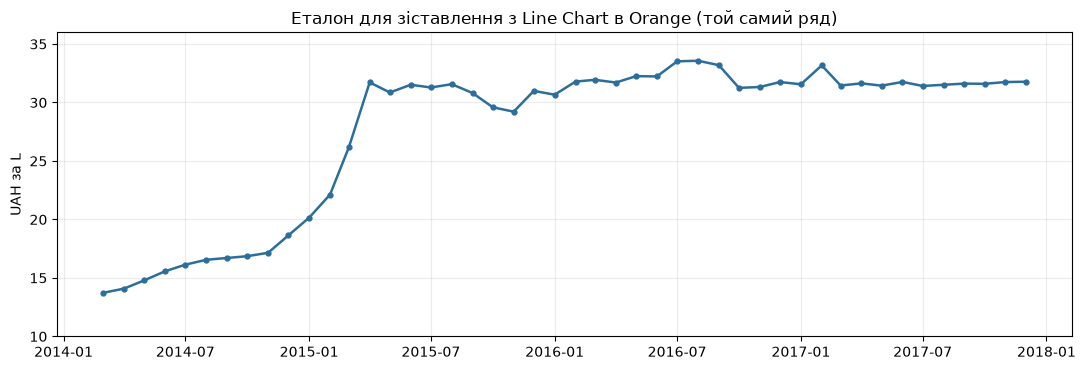

In [23]:
# Завдання 11. Потік опрацювання даних: перевірка, що Orange отримає ті самі дані
orange_in = pd.read_csv('ряд_для_orange.csv', parse_dates=['date'])
print('Типи стовпців у Python:', orange_in.dtypes.astype(str).to_dict())
print('Дати збігаються із сіткою:', bool((orange_in['date'] == GRID).all()),
      '| ціни збігаються з рядом Python:', bool(np.allclose(orange_in['price'], series.values, atol=1e-4)))
print('Порожніх значень у файлі:', int(orange_in['price'].isna().sum()), '(Interpolate нічого не змінить)')

fig, ax = plt.subplots()
ax.plot(orange_in['date'], orange_in['price'], color='#2C6E9B', lw=1.8, marker='o', ms=3.5)
ax.set_ylim(10, 36); ax.set_ylabel(f'{CURRENCY} за {UNIT}')
ax.set_title('Еталон для зіставлення з Line Chart в Orange (той самий ряд)')
plt.tight_layout(); plt.show()

**Висновок до завдання 11:**

Потік у Orange: `File` -> `As Timeseries` -> `Interpolate` -> `Line Chart`. У `File` завантажено `ряд_для_orange.csv`, `date` розпізнано як **time** (формат ISO), `price` як **numeric** і задано роль **target** (вона потрібна далі віджету Model Evaluation). У `As Timeseries` обрано `date` як часову змінну.

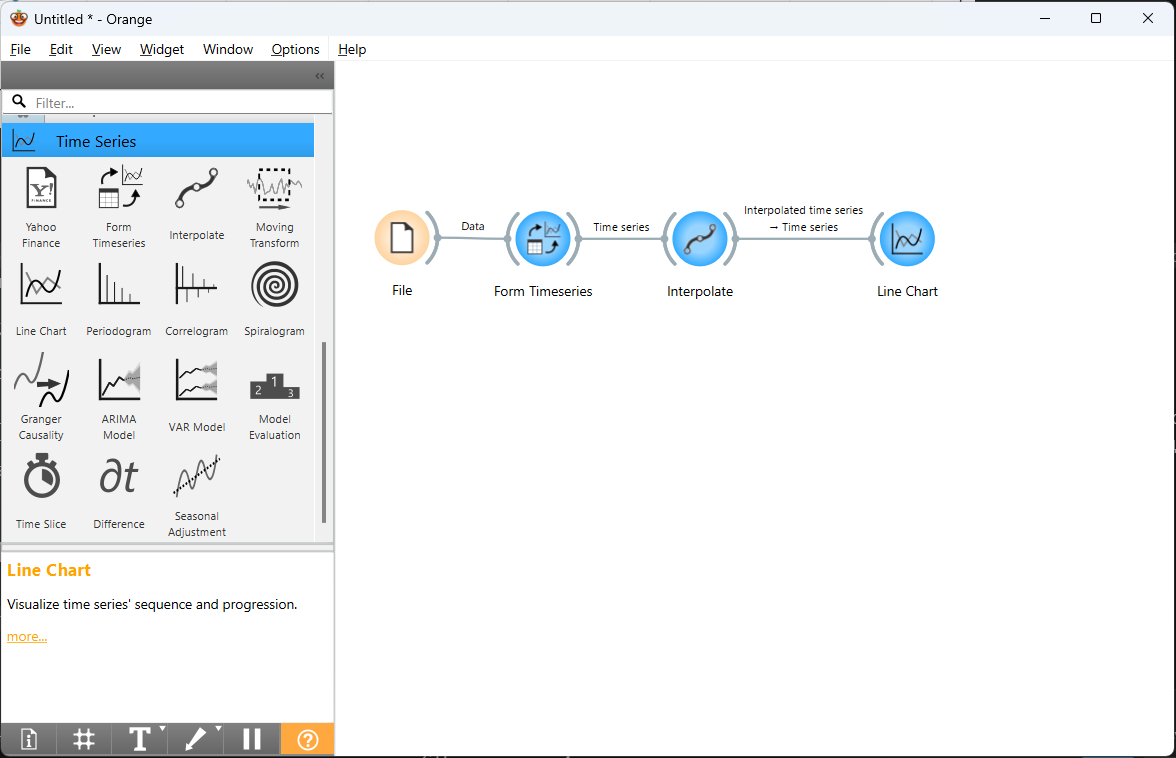

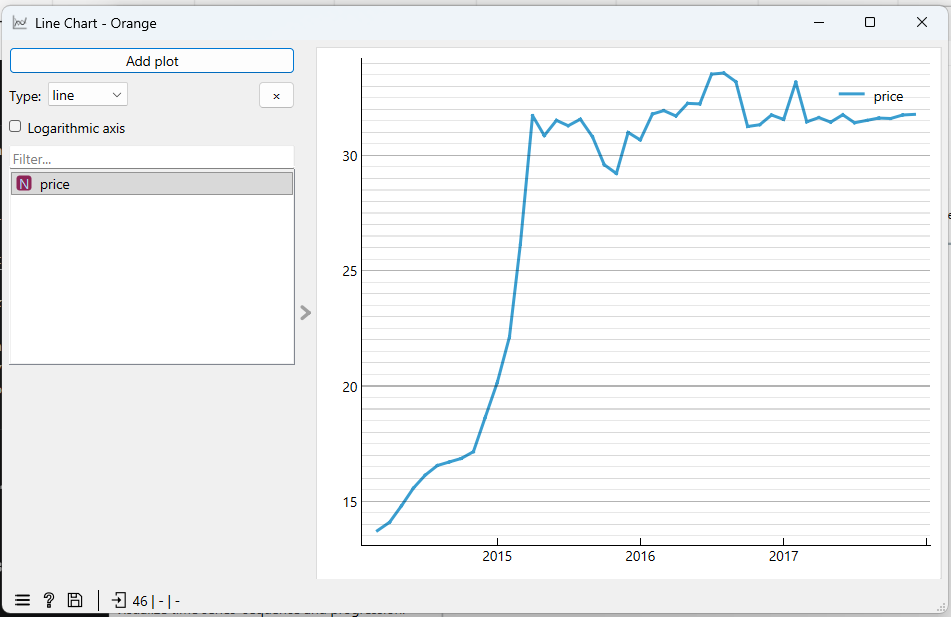

Перевірка в Python (клітинка вище) показала, що файл містить рівно ті самі 46 значень і дати, що ряд із Частини 1, а порожніх значень немає, тож `Interpolate` нічого не змінює. Графік у Orange має збігатися з графіком 1 із завдання 3: ряд починається біля 13.7 у 03.2014, різко зростає в 03-04.2015 до приблизно 31.7 і далі тримається в коридорі близько 29 - 34. *(підтвердіть збіг за своїм знімком)*

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

          ряд функція лаги на графіку Orange значущі в Orange значущі за statsmodels (лаги 1-20)
 вихідний ряд     ACF               [28, 33]               []           [1, 2, 3, 4, 5, 6, 7, 8]
 вихідний ряд    PACF            [9, 14, 20]               []                                [1]
перша різниця     ACF        [6, 11, 19, 27]               []                                [1]
перша різниця    PACF            [6, 11, 18]               []                                [1]

Класичний сезонний профіль: розмах 3.65; STL (середнє за місяцем): розмах 3.39; кореляція профілів 0.94
Максимум профілю: класичний - місяць 4, STL - місяць 4; мінімум: класичний - місяць 11, STL - місяць 1
Розмах класичної сезонної складової / розмах ряду: 18.4%
Середнє |ряд - скоригований ряд| = 1.10 UAH/L


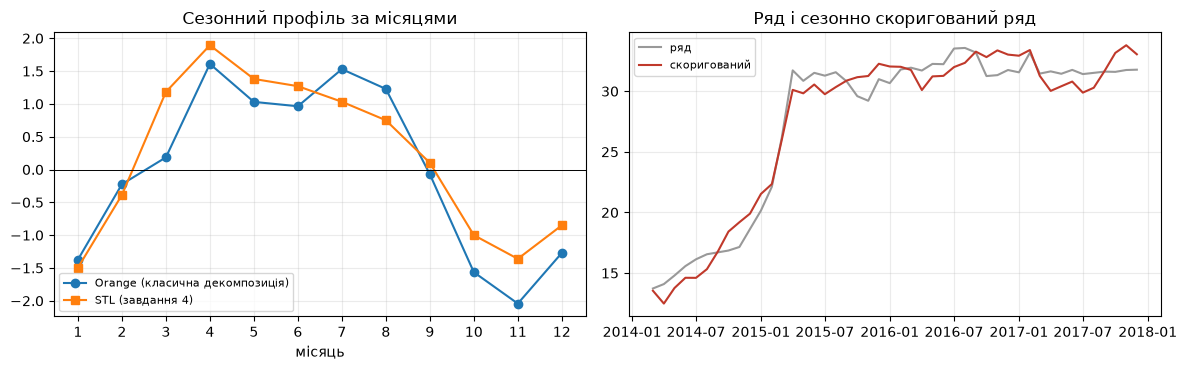

In [24]:
# Завдання 12. Автокореляція та диференціювання: що саме малює Orange
from scipy.signal import argrelextrema
from statsmodels.tsa.seasonal import seasonal_decompose

def orange_correlogram(x, partial=False):
    """Відтворення логіки віджета Correlogram (Orange3-Timeseries): лише локальні екстремуми |ACF|, order=3."""
    n = len(x)
    c = pacf(x, nlags=min(n // 2 - 1, n - 1), method='ldb') if partial else acf(x, nlags=int(.9 * n), fft=True)
    lags = argrelextrema(np.abs(c), np.greater, order=3)[0]
    vals = c[lags]
    band = 1.96 * np.sqrt((1 + 2 * (vals ** 2).sum()) / n)
    return lags, vals, band

level = series.values
# віджет Difference залишає перше значення порожнім, а Correlogram інтерполює його
diff_orange = pd.Series(np.r_[np.nan, np.diff(level)]).interpolate(limit_direction='both').values

rows = []
for name, x in [('вихідний ряд', level), ('перша різниця', diff_orange)]:
    for kind, part in [('ACF', False), ('PACF', True)]:
        lags, vals, band = orange_correlogram(x, part)
        full = pacf(x, nlags=20, method='ywm') if part else acf(x, nlags=20)
        classic = 1.96 / np.sqrt(len(x))
        rows.append({'ряд': name, 'функція': kind,
                     'лаги на графіку Orange': lags.tolist(),
                     'значущі в Orange': [int(l) for l, v in zip(lags, vals) if abs(v) > band],
                     'значущі за statsmodels (лаги 1-20)': [l for l in range(1, 21) if abs(full[l]) > classic]})
print(pd.DataFrame(rows).to_string(index=False))

# сезонне коригування (адитивна модель, період 12, як у віджеті Seasonal Adjustment за замовчуванням)
dec = seasonal_decompose(level, model='additive', period=12)
adjusted = level - dec.seasonal
stl_profile = stl_res.seasonal.groupby(stl_res.seasonal.index.month).mean()
classic_profile = pd.Series(dec.seasonal[:12], index=series.index[:12].month).sort_index()
print(f'\nКласичний сезонний профіль: розмах {classic_profile.max() - classic_profile.min():.2f}; '
      f'STL (середнє за місяцем): розмах {stl_profile.max() - stl_profile.min():.2f}; '
      f'кореляція профілів {np.corrcoef(classic_profile.values, stl_profile.values)[0, 1]:.2f}')
print(f'Максимум профілю: класичний - місяць {classic_profile.idxmax()}, STL - місяць {stl_profile.idxmax()}; '
      f'мінімум: класичний - місяць {classic_profile.idxmin()}, STL - місяць {stl_profile.idxmin()}')
print(f'Розмах класичної сезонної складової / розмах ряду: {(dec.seasonal.max() - dec.seasonal.min()) / (level.max() - level.min()):.1%}')
print(f'Середнє |ряд - скоригований ряд| = {np.abs(level - adjusted).mean():.2f} {CURRENCY}/{UNIT}')

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(range(1, 13), classic_profile.values, marker='o', label='Orange (класична декомпозиція)')
axes[0].plot(range(1, 13), stl_profile.values, marker='s', label='STL (завдання 4)')
axes[0].axhline(0, color='black', lw=.7); axes[0].set_xticks(range(1, 13)); axes[0].legend(fontsize=8)
axes[0].set_title('Сезонний профіль за місяцями'); axes[0].set_xlabel('місяць')
axes[1].plot(series.index, level, color='#999999', label='ряд'); axes[1].plot(series.index, adjusted, color='#C0392B', label='скоригований')
axes[1].legend(fontsize=8); axes[1].set_title('Ряд і сезонно скоригований ряд')
plt.tight_layout(); plt.show()

**Висновок до завдання 12:**

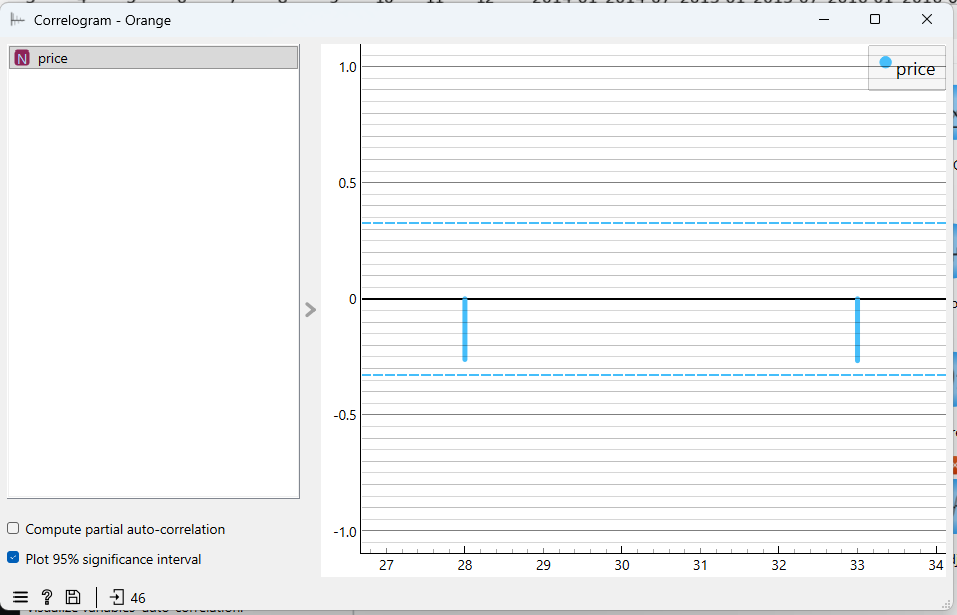
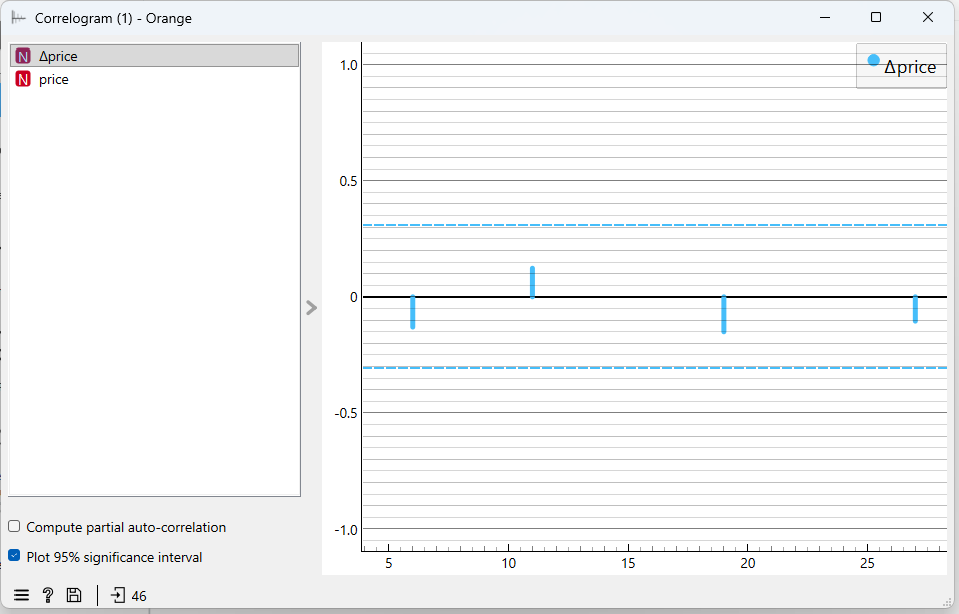
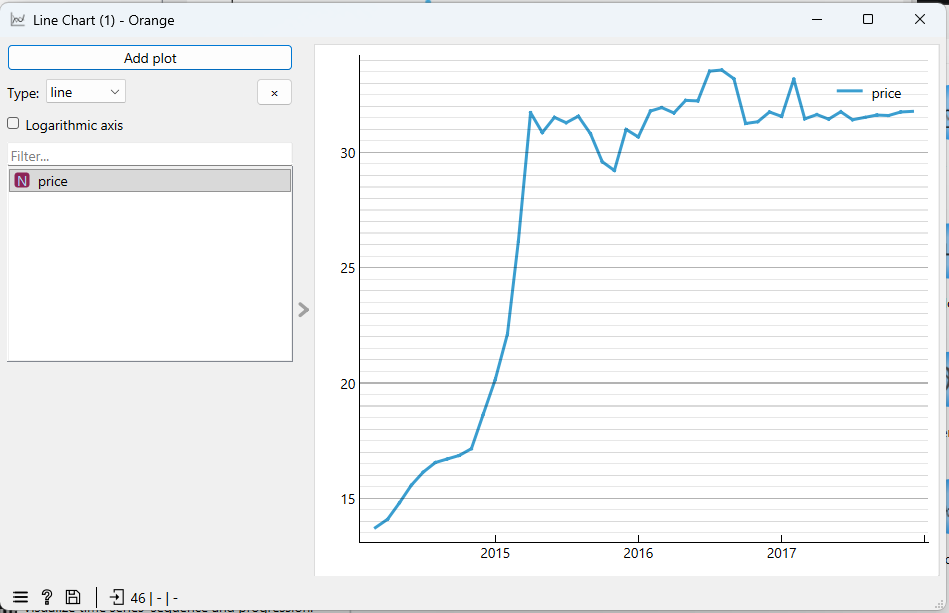

**Зіставлення з ACF із завдання 5: висновки про значущі лаги не збігаються, хоч числа однакові.** Віджет Correlogram викликає ті самі функції statsmodels, тож значення автокореляцій у тих самих лагах ідентичні. Але, за кодом Orange3-Timeseries (v0.6.3), він малює не всі лаги, а лише локальні екстремуми |ACF| (вікно 3), і довірчу смугу рахує за іншою формулою, ніж statsmodels. У результаті для вихідного ряду Orange показує лише лаги 28 і 33 (ACF) та 9, 14, 20 (PACF), жоден не значущий, тоді як statsmodels показує значущі лаги 1 - 8 у ACF. Для першої різниці Orange показує лаги 6, 11, 19, 27 (ACF) і 6, 11, 18 (PACF), також без значущих, а значущий лаг 1 (0.30), який видно у statsmodels, на корелограмі Orange відсутній, бо не є локальним екстремумом. Практичний наслідок: порядок ARIMA не можна вибирати за корелограмою Orange без перевірки в Python. *(звірте перелік лагів зі своїм знімком: якщо версія додатка інша, картина може відрізнятися)*

**Сезонне коригування** (адитивна модель, період 12). Сезонний профіль Orange має розмах 3.65 грн, профіль STL (середнє за місяцем) 3.39 грн; профілі корелюють на 0.94, обидва мають максимум у квітні. Тобто два методи бачать одну й ту саму закономірність, але це не доводить її реальності: квітень це місяць стрибка 2015 року, а розмах сезонної складової в STL згасає з 5.33 до 2.05 грн (завдання 4). Узгодженість Orange і STL підтверджує лише, що обидва методи реагують на одні й ті самі дані.

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

In [25]:
# Завдання 13. Модель і оцінювання: які фолди перевіряє Orange
MAX_ORDER = 1                      # в Orange max_order моделі ARIMA(1,1,1) = max(p, d, q) = 1

def orange_ok(n_folds, steps):
    return n_folds * steps + MAX_ORDER <= N

print(f'Довжина ряду N = {N}')
print(f'Типові налаштування: 20 x 3 + {MAX_ORDER} = {20 * 3 + MAX_ORDER} > {N}  ->  перевірка пройшла б: {orange_ok(20, 3)}')
print('Повідомлення Orange: "Unexpected error: Supplied time series is too short for this many folds / step size. Retry with fewer iterations."')
print(f'Наші налаштування: 7 x 3 + {MAX_ORDER} = {7 * 3 + MAX_ORDER} <= {N}  ->  {orange_ok(7, 3)}')
print(f'Максимум фолдів при 3 кроках: {(N - MAX_ORDER) // STEPS}; максимум кроків при 7 фолдах: {(N - MAX_ORDER) // 7}\n')

rows = []
for fold in range(1, N_FOLDS + 1):                 # нумерація Orange: фолд 1 = найпізніший
    end = N - fold * STEPS
    rows.append({'фолд Orange': fold, 'навчання (рядки)': f'1-{end}', 'навчання (період)': f'03.2014 - {series.index[end - 1]:%m.%Y}',
                 'тест (період)': f'{series.index[end]:%m.%Y} - {series.index[end + STEPS - 1]:%m.%Y}', 'розмір навчання': end})
print(pd.DataFrame(rows).to_string(index=False))
print('\nПеревірка збігу з фолдами Python (хронологічно):', [(a, b) for a, b in FOLDS] == [(N - f * STEPS, N - f * STEPS + STEPS) for f in range(7, 0, -1)])
print('Тестові вікна не перекриваються й покривають останні', N_FOLDS * STEPS, 'місяців; серпень 2017 (заповнений) потрапляє у фолд 2')

Довжина ряду N = 46
Типові налаштування: 20 x 3 + 1 = 61 > 46  ->  перевірка пройшла б: False
Повідомлення Orange: "Unexpected error: Supplied time series is too short for this many folds / step size. Retry with fewer iterations."
Наші налаштування: 7 x 3 + 1 = 22 <= 46  ->  True
Максимум фолдів при 3 кроках: 15; максимум кроків при 7 фолдах: 6

 фолд Orange навчання (рядки) навчання (період)     тест (період)  розмір навчання
           1             1-43 03.2014 - 09.2017 10.2017 - 12.2017               43
           2             1-40 03.2014 - 06.2017 07.2017 - 09.2017               40
           3             1-37 03.2014 - 03.2017 04.2017 - 06.2017               37
           4             1-34 03.2014 - 12.2016 01.2017 - 03.2017               34
           5             1-31 03.2014 - 09.2016 10.2016 - 12.2016               31
           6             1-28 03.2014 - 06.2016 07.2016 - 09.2016               28
           7             1-25 03.2014 - 03.2016 04.2016 - 06.2016      

**Висновок до завдання 13:**

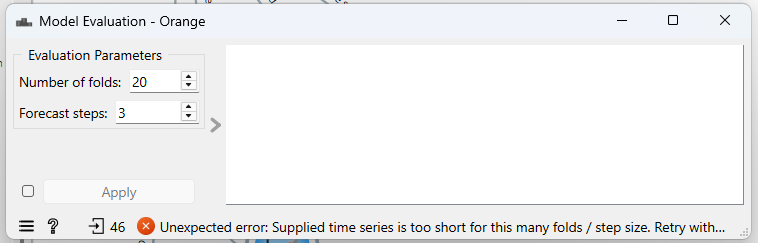
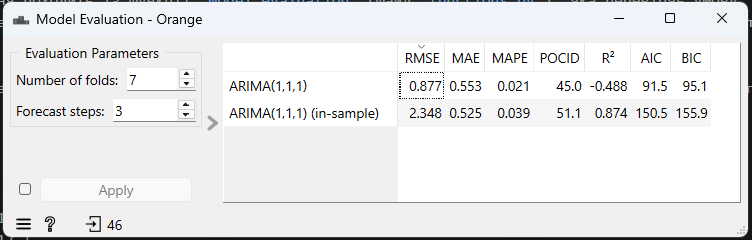

У таблиці два рядки: `ARIMA(1,1,1)` (позавибіркова перевірка на 7 фолдах) та `ARIMA(1,1,1) (in-sample)` (оцінка підігнаних значень на всьому ряді). Для порівняння з Python використовується перший рядок: RMSE 0.877, MAE 0.553, MAPE 0.021, POCID 45.0. *(перенесіть значення зі свого знімка; якщо вони відрізняються в 3-му знаку, причиною може бути інша версія statsmodels)*

**Типові налаштування (20 фолдів x 3 кроки).** Orange відмовляється рахувати й показує: *Unexpected error: Supplied time series is too short for this many folds / step size. Retry with fewer iterations.* Повідомлення походить із функції `model_evaluation` (файл `functions.py`), яка перевіряє умову `n_folds * forecast_steps + max_lag > len(data)`. Тут max_lag це найбільший порядок моделі, для ARIMA(1,1,1) він дорівнює 1. Для типових налаштувань: 20 x 3 + 1 = 61 > 46, тобто потрібно щонайменше 61 місяць, а в ряді їх 46. Для 7 x 3 + 1 = 22 <= 46 перевірка проходить. Максимум фолдів при 3 кроках становить 15.

**Які 7 фолдів.** Навчання завжди починається з першого місяця й розширюється (початок не рухається), тестові вікна по 3 місяці не перекриваються й покривають останні 21 місяць. Нумерація Orange іде від найпізнішого:

| Фолд Orange | Навчання | Тест |
|---|---|---|
| 1 | 03.2014 - 09.2017 (43 рядки) | 10.2017 - 12.2017 |
| 2 | 03.2014 - 06.2017 (40) | 07.2017 - 09.2017 |
| 3 | 03.2014 - 03.2017 (37) | 04.2017 - 06.2017 |
| 4 | 03.2014 - 12.2016 (34) | 01.2017 - 03.2017 |
| 5 | 03.2014 - 09.2016 (31) | 10.2016 - 12.2016 |
| 6 | 03.2014 - 06.2016 (28) | 07.2016 - 09.2016 |
| 7 | 03.2014 - 03.2016 (25) | 04.2016 - 06.2016 |

Це ті самі відрізки, що в Python (хронологічно фолди 7, 6, ..., 1).

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [26]:
# Завдання 14. Чому числа не збігаються
# Значення з таблиці Model Evaluation в Orange, рядок ARIMA(1,1,1) (не "in-sample"). Перенесіть зі свого знімка.
ORANGE = {'RMSE': 0.877, 'MAE': 0.553, 'MAPE': 0.021, 'POCID': 45.0}

# Orange збирає прогнози фолдами в порядку 1, 2, ..., 7 (від найпізнішого), тому змінюємо порядок блоків
order = np.arange(N_FOLDS * STEPS).reshape(N_FOLDS, STEPS)[::-1].ravel()
true_o, pred_o = arima_true[order], arima_pred[order]
err = true_o - pred_o

repro = {
    'RMSE':  np.sqrt(np.mean(err ** 2)),
    'MAE':   np.median(np.abs(err)),
    'MAPE':  np.mean(np.abs(err)) / np.mean(np.abs(true_o)),
    'POCID': 100 * np.mean(np.diff(true_o) * np.diff(pred_o) > 0),
}
formulas = {
    'RMSE':  'sqrt(mean((y - f)^2))',
    'MAE':   'median(|y - f|)  (медіана, а не середнє)',
    'MAPE':  'mean(|y - f|) / mean(|y|)  (частка, не відсотки; не середнє по точках)',
    'POCID': '100 * mean(diff(y) * diff(f) > 0) на склеєному векторі прогнозів',
}
tab = pd.DataFrame({'Orange': ORANGE, 'Python (відтворення)': repro, 'формула': formulas})
tab['збіг до 3-го знака'] = [abs(ORANGE[k] - repro[k]) < 5e-4 + (0.05 if k == 'POCID' else 0) for k in tab.index]
pd.set_option('display.max_colwidth', 80)
print(tab.round(4).to_string())

print('\nТе саме, що зазвичай позначають цими назвами (завдання 7 і 15):')
print(f'  MAE (середнє)      = {arima_m["MAE"]:.3f}   проти медіани Orange {repro["MAE"]:.3f}')
print(f'  MAPE (по точках)   = {arima_m["MAPE, %"]:.3f}%  проти Orange {repro["MAPE"] * 100:.3f}% (частка x 100)')
print(f'  RMSE               = {arima_m["RMSE"]:.3f}   проти Orange {repro["RMSE"]:.3f}')
within = [i for i in range(len(true_o) - 1) if (i + 1) % STEPS != 0]
dt, dp = np.diff(true_o), np.diff(pred_o)
print(f'  POCID: із {len(dt)} різниць {len(dt) - len(within)} беруть дві сусідні точки з РІЗНИХ фолдів (кінець одного вікна, початок іншого)')
print(f'  POCID лише по різницях усередині фолду: {100 * np.mean(dt[within] * dp[within] > 0):.1f}% проти {repro["POCID"]:.1f}% в Orange')

       Orange  Python (відтворення)                                                                 формула  збіг до 3-го знака
RMSE    0.877                0.8767                                                   sqrt(mean((y - f)^2))                True
MAE     0.553                0.5525                                median(|y - f|)  (медіана, а не середнє)                True
MAPE    0.021                0.0214  mean(|y - f|) / mean(|y|)  (частка, не відсотки; не середнє по точках)                True
POCID  45.000               45.0000        100 * mean(diff(y) * diff(f) > 0) на склеєному векторі прогнозів                True

Те саме, що зазвичай позначають цими назвами (завдання 7 і 15):
  MAE (середнє)      = 0.684   проти медіани Orange 0.553
  MAPE (по точках)   = 2.133%  проти Orange 2.140% (частка x 100)
  RMSE               = 0.877   проти Orange 0.877
  POCID: із 20 різниць 6 беруть дві сусідні точки з РІЗНИХ фолдів (кінець одного вікна, початок іншого)
  POCID лише по р

**Висновок до завдання 14:**

| Метрика | Orange | Python (відтворення) | Формула |
|---|---|---|---|
| RMSE | 0.877 | 0.8767 | sqrt(mean((y - f)^2)) |
| MAE | 0.553 | 0.5525 | median(\|y - f\|), **медіана** абсолютної помилки |
| MAPE | 0.021 | 0.0214 | mean(\|y - f\|) / mean(\|y\|), частка, не відсотки |
| POCID | 45.0 | 45.0 | 100 * mean(diff(y) * diff(f) > 0) на склеєному векторі |

Усі чотири значення відтворено до третього знака (клітинка вище виводить «збіг» для кожної).

**Яка метрика не відповідає назві.** Найяскравіше **MAE**: у Orange це медіана, а не середнє абсолютних похибок (у коді `functions.py` docstring прямо називає її Median absolute error). Звичайний MAE моделі дорівнює 0.684 (завдання 7), а Orange показує 0.553, бо медіана ігнорує кілька великих похибок весни 2015 року. Також **MAPE** не класична: це сума абсолютних похибок, поділена на середній рівень ряду, у вигляді частки (0.0214), а не середнє відсоткових похибок по точках, виражене у відсотках (2.133%); на цьому майже сталому ряді числа близькі, але формули різні. **POCID** теж відрізняється: рахується на склеєному векторі прогнозів усіх фолдів (у порядку фолдів 1, 2, ..., 7), тож 6 із 20 різниць порівнюють сусідні точки з різних фолдів, і до того ж плоска зміна рахується промахом; по різницях усередині фолдів було б 57.1% замість 45.0%.

**Що збіглося одразу:** RMSE (0.877 в обох), бо формула однакова й обчислюється на тих самих 21 парах «факт - прогноз»; від порядку фолдів і від складання прогнозів докупи вона не залежить.

**Висновок.** Розбіжність не є помилкою Orange: однакові назви позначають різні формули. Перш ніж порівнювати числа з двох інструментів, треба перевірити (1) формулу кожної метрики в коді (середнє чи медіана, що в знаменнику, частка чи відсотки), (2) що дані й фолди ідентичні, (3) як складаються прогнози фолдів докупи і в якому порядку, (4) одиниці виміру.

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [27]:
# Завдання 15. Матриця напрямку зміни
from scipy.stats import binomtest

dt, dp = np.diff(true_o), np.diff(pred_o)          # та сама послідовність, що в POCID Orange
lab = {1: 'зросла', -1: 'впала', 0: 'без змін'}
cm = pd.crosstab(pd.Series(np.sign(dt)).map(lab).rename('насправді'), pd.Series(np.sign(dp)).map(lab).rename('передбачено'))
cm = cm.reindex(index=['зросла', 'впала'], columns=['зросла', 'впала'], fill_value=0)
print('Матриця за визначенням POCID в Orange (різниці склеєного вектора):'); print(cm.to_string())
correct = cm.loc['зросла', 'зросла'] + cm.loc['впала', 'впала']
print(f'Правильно {correct} із {len(dt)} -> {100 * correct / len(dt):.1f}%; POCID Orange = {ORANGE["POCID"]:.1f}%  '
      f'(збіг: {abs(100 * correct / len(dt) - ORANGE["POCID"]) < 0.05})')

# напрямок відносно останнього відомого значення: саме це потрібне для рішення "купувати чи чекати"
last_known = np.repeat([y[end - 1] for end, _ in FOLDS], STEPS)
true_dir, pred_dir = np.sign(arima_true - last_known), np.sign(arima_pred - last_known)
cm2 = pd.crosstab(pd.Series(true_dir).map(lab).rename('насправді'), pd.Series(pred_dir).map(lab).rename('передбачено'))
cm2 = cm2.reindex(index=['зросла', 'впала'], columns=['зросла', 'впала'], fill_value=0)
print('\nМатриця за напрямком відносно останнього відомого значення (по кожній з 21 прогнозної точки):'); print(cm2.to_string())
ok2 = cm2.loc['зросла', 'зросла'] + cm2.loc['впала', 'впала']
n2 = int(cm2.values.sum())
print(f'Правильно {ok2} із {n2} -> {100 * ok2 / n2:.1f}%; частка місяців, коли ціна зросла: {(true_dir > 0).mean():.1%}')
print(f'Біноміальний тест проти 50%: p = {binomtest(int(ok2), n2, 0.5).pvalue:.2f}')
print(f'Точність "завжди кажемо зросте": {(true_dir > 0).mean():.1%}; "завжди кажемо впаде": {(true_dir < 0).mean():.1%}')

Матриця за визначенням POCID в Orange (різниці склеєного вектора):
передбачено  зросла  впала
насправді                 
зросла            7      5
впала             6      2
Правильно 9 із 20 -> 45.0%; POCID Orange = 45.0%  (збіг: True)

Матриця за напрямком відносно останнього відомого значення (по кожній з 21 прогнозної точки):
передбачено  зросла  впала
насправді                 
зросла            8      2
впала             7      4
Правильно 12 із 21 -> 57.1%; частка місяців, коли ціна зросла: 47.6%
Біноміальний тест проти 50%: p = 0.66
Точність "завжди кажемо зросте": 47.6%; "завжди кажемо впаде": 52.4%


**Висновок до завдання 15:**

**Матриця за означенням POCID в Orange** (різниці склеєного вектора, 20 різниць):

| Насправді \ Передбачено | зросла | впала |
|---|---|---|
| **зросла** | 7 | 5 |
| **впала** | 6 | 2 |

Правильних передбачень 7 + 2 = 9 із 20, тобто **45.0%**, що збігається з POCID у таблиці Orange (45.0).

**Для рішення «купувати зараз чи чекати»** потрібна інша матриця: напрям прогнозу відносно останнього відомого значення в кожному фолді (21 точка):

| Насправді \ Передбачено | зросла | впала |
|---|---|---|
| **зросла** | 8 | 2 |
| **впала** | 7 | 4 |

Правильних 12 із 21 (57.1%); біноміальний тест проти 50% дає p = 0.66, тобто від підкидання монети це не відрізняється. Ціна зростала в 47.6% місяців, тож «завжди прогнозувати падіння» дало б 52.4%. Модель 15 разів із 21 прогнозує зростання й з 11 випадків падіння вгадує лише 4.

**Висновок.** Для рішення купувати чи чекати модель **не корисна**: прямих доказів вмінні вгадувати напрям немає. Це питання інше, ніж те, на яке відповідають MAE та RMSE. Вони вимірюють розмір похибки в гривнях, і на майже пласкому ряді навіть наївний прогноз має малу похибку (MAE 0.6 грн), хоча напрям зміни при цьому вгадується як випадковий. Матриця ж оцінює знак зміни, а не її розмір, і типова місячна зміна (близько 0.4 грн) тут порівнянна з шумом.

---
# Загальний висновок

Напишіть 8–12 речень, які відповідають на такі питання:

1. Чи є у вашому ряді сезонність і чим ви це довели?
2. Який метод прогнозування виявився найкращим і чи перевершив він найпростіший базис?
3. Чи знайшли ви точку зміни режиму; якщо так — чи є для неї зовнішнє пояснення?
4. Чому однаково названі метрики у двох середовищах дали різні числа?
5. Чого ви не змогли встановити через те, що ряд має лише 46 спостережень?

1. **Сезонність.** Формально F_S = 0.842 перевищує поріг 0.64, але я її не вважаю доведеною: у робастного STL F_S = 0.445, розмах сезонної складової згасає (5.33, 2.66, 2.05 грн за 2015-2017), профілі 2016 і 2017 років не корелюють (-0.20), а сезонний наївний прогноз удвічі гірший за наївний. Квітневий пік сезонного профілю збігається з місяцем стрибка 2015 року.
2. **Найкращий метод.** Наївний прогноз (MAE 0.626, RMSE 0.886, MAPE 1.94%) на 7 фолдах по 3 кроки. ARIMA(1,1,1) (0.684, 0.877, 2.13%) його не перевершила: вона гірша за MAE і MAPE та краща лише на 1% за RMSE, тож права на існування не має.
3. **Точка зміни.** Знайдено 03.2015 (t = 26.2; p = 0.004 за тестом перестановок), рівень зріс із 16.87 до 31.46 грн/л (у 1.86 раза). Зовнішнє пояснення: гостра девальвація гривні, коли НБУ 5 лютого 2015 року перейшов до плаваючого курсу, а офіційний курс у лютому 2015 досяг історичного мінімуму близько 30 грн за долар (цей факт варто підтвердити посиланням на дані НБУ); ціна в магазині реагувала із запізненням у 1-2 місяці й після цього не повернулася до колишніх значень.
4. **Метрики.** Однаково названі метрики дали різні числа, бо формули різні: MAE в Orange це медіана (0.553 проти 0.684), MAPE це частка, поділена на середній рівень, а POCID рахується на склеєному векторі фолдів (45.0% проти 57.1% усередині фолдів); збігся лише RMSE, бо його формула однакова. Усі значення відтворено до третього знака.
5. **Чого не вдалося встановити.** У ряді лише 46 спостережень (менше чотирьох років), тож не можна надійно відрізнити сезонність від одноразового шоку 2015 року; 21 прогнозна точка не дозволяє відрізнити різницю в 1% між ARIMA і наївним від шуму; є лише одна точка зміни, тому не відомо, чи такі зсуви повторюються; а заповнений серпень 2017 не дозволяє оцінити похибку для цього місяця.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

Заповніть таблицю. Якщо ШІ не використовувався, напишіть «не використовувався» в першому рядку
й залиште решту порожньою.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | Gemini |
| Для яких саме завдань | 3, 4, 5, 7, 9 |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | код / пояснення |
| Що ви змінили у згенерованому результаті й чому | після пояснення перефразовував відповіді у своїх словах, спрощував код, якого не було потрібно |
| Що з отриманого ви **перевірили самостійно** і яким способом | Перевірив кожну відповідь до питань перечитуючи їх, співвідношення даних |
| Чи траплялися у відповідях ШІ помилки; якщо так — які | так, більшість у частині про Orange через застарілі дані |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: Ореньчук Юрій  Дата: 23.10.26